# Task 29 — Contract review assistant: which clauses need a lawyer before signature

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Atticus Open Contract Dataset (CUAD v1)](https://www.kaggle.com/datasets/konradb/atticus-open-contract-dataset-aok-beta) — 510 commercial contracts from public SEC filings, 13,823 clause annotations in 41 categories, by The Atticus Project (CC BY 4.0)
**Task family:** clause extraction without an LLM, knowledge graph (RDF + SHACL), capacity-based operating point · **Companion tasks:** `04_erp_document_rag.ipynb` (retrieval without an LLM), `03_complaint_triage_text.ipynb` (text classification)

---

## The task card

> **Board question.** *Legal operations receives about 40 third-party contracts a month and can give each one about 30 minutes of a lawyer's time: roughly 20 highlighted passages. Can an assistant choose those 20 so that the lawyer sees at least 80 % of the clauses that block signature, says which ones it did not find, and keeps doing so when the business starts signing a kind of contract it has never seen?*

**Business context.** Contract review sits just before signature. The legacy estate is a shared mailbox or a contract-lifecycle-management (CLM) tool, Word redlines, a key-terms spreadsheet and outside counsel. The assistant follows Session 01's *human-in-the-loop* pattern: it highlights, a lawyer decides. Its risks are a clause the lawyer never sees and a summary that reads like advice.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **clause extractor**, packaged and reproducible, evaluated per category on unseen contracts, with the four traps guarded by tests;
2. an **operating point set by the lawyer's capacity**, recorded as an ADR;
3. a **knowledge layer** (a SHACL-validated clause taxonomy, a party–obligation graph) and the ablation that prices it;
4. the **operational wrapper**: package, `POST /review`, CI gate, registry, model card, monitoring for new contract types.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Human-in-the-loop review between intake, CLM tool and counsel; the "not legal advice" boundary |
| 2 · MLOps | Evaluation grouped by contract; a capacity-based gate; drift by contract type; corrections as delayed labels |
| 3 · Semantic layer | The clause taxonomy as an ontology; SHACL over annotations; a party–obligation graph |
| 4 · LLM/RAG | Chunking that respects clauses; lexicon-guided retrieval; a cited risk summary with a refusal path (Stretch) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The baseline runs **without any LLM**, so extraction is measured before a generator can hide it. Four traps are left in, flagged ⚠.

**Honesty note.** The contracts are **real** agreements filed with the SEC by US-listed companies (EDGAR, with the filers' redactions); the labels come from trained law students, reviewed by attorneys. Two things are not real: the "red-flag" list, an assumption standing in for a legal-operations lead's, and franchise agreements arriving as new business (Section 7), simulated by holding that type out of training. Nothing here is legal advice.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, contract types and first look | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | Chunking and the clause extractor, the traps, the clause taxonomy and party–obligation graph, the 20-highlight operating point | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | A contract type the extractor has never seen (simulated), the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `mask_same_length`, `load_cuad` and `contract_type` (Section 1); `make_chunks`, `label_chunks`, `bm25_matrix`, `fit_linear` and `calibrate` (Section 3); the taxonomy, `shacl_violations`, `zs` and `obligation_graph` (Section 5); `review_pack` and `pack_eval` (Section 6).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 297 training, 99 validation and 99 test contracts (63,641, 19,001 and 21,461 chunks), with 15 franchise agreements held out; macro AUPR 0.489 on test (0.499 with the KB retriever at weight 0.25); at 20 highlights per contract, red-flag recall 88.0 % on test, about €4,000 a month at the assumed rate and volume (15 highlights reach 80 % on validation); 53.3 % on the unseen franchise agreements.
- **Runtime:** about 3–4 minutes on a laptop (181 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
import rdflib
import pyshacl
from rdflib import Graph, Namespace, Literal
from rdflib.namespace import RDF, RDFS, SKOS
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer, TfidfTransformer, CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from scipy.stats import binom
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 80)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                       # kept for symmetry with the other tasks; the linear models here are single-threaded
KAGGLE_HANDLE = "konradb/atticus-open-contract-dataset-aok-beta"
SPLIT = (0.6, 0.2, 0.2)          # train / validation / test, by contract family (never by clause)
FILING_YEAR_SPLIT = 2010         # no time axis drives this data; filing year is only used for a drift check
HELD_OUT_TYPE = "Franchise"      # simulated new business: this contract type never reaches training
DUP_COSINE = 0.80                # contracts at least this similar (TF-IDF cosine) form one family for splitting
NEG_SAMPLE = 0.25                # share of all-negative training chunks kept (sampling rule; all positives kept)
MAX_FEATURES = 150_000           # TF-IDF vocabulary cap; lower it on a small laptop
K_HIGHLIGHTS = 3                 # highlights per category per contract when scoring precision/recall@k
# business constants: assumptions, to be varied and signed off in task C3
LAWYER_HIGHLIGHTS = 20           # review capacity: passages a lawyer reads per incoming contract (≈ 30 minutes)
SECONDS_PER_HIGHLIGHT = 90       # assumption: reading and judging one highlighted passage
LAWYER_EUR_PER_HOUR = 200.0      # assumption: blended in-house / outside-counsel rate
CONTRACTS_PER_MONTH = 40         # assumption: incoming third-party contracts per month
TARGET_RECALL = 0.80             # assumption: share of red-flag clauses the lawyer must see
TYPE_DOUBT_RATE = 0.10           # assumption: share of familiar contracts the intake type check may flag for review
RED_FLAGS = ["Change Of Control", "Anti-Assignment", "Non-Compete", "Exclusivity", "No-Solicit Of Customers",
             "Most Favored Nation", "Rofr/Rofo/Rofn", "Termination For Convenience", "Minimum Commitment",
             "Ip Ownership Assignment", "Uncapped Liability", "Cap On Liability", "Liquidated Damages",
             "Covenant Not To Sue"]   # assumption: the legal-ops lead's list of clauses that block signature

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "cuad", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn
print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · networkx {nx.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · scikit-learn 1.9.1 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `mask_same_length`, `load_cuad` and `contract_type`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `konradb/atticus-open-contract-dataset-aok-beta`, a mirror of CUAD v1 by The Atticus Project (Hendrycks et al., 2021) |
| **Licence** | CC BY 4.0 (attribute The Atticus Project); its README makes no representation on the licence of the contracts themselves, public EDGAR filings |
| **Provenance** | Real contracts filed with the SEC, 25 types; labelled by law students, reviewed by attorneys |
| **Size** | 510 contracts, 26.8 M characters (median 33,143, longest 338,211); 41 categories × 510 = 20,910 question rows; 13,823 annotated spans; 6,702 contract–category pairs (32 %) contain a clause |
| **Files** | Used: `CUAD_v1/CUAD_v1.json` (40 MB) and the README. Not used: a CSV, 28 spreadsheets, 510 PDFs, 510 TXTs (174 MB in all) |
| **Schema** | SQuAD 2.0: `title`; `paragraphs[0].context` (the whole contract); `qas[]`: `question`, `is_impossible`, `answers[{text, answer_start}]` |
| **Label** | Character spans per category; no span means the clause is absent |
| **Window used here** | All 510. The 15 franchise agreements are held out as simulated new business; the other 495 split 297 / 99 / 99 by contract family. Filing years (from titles): 1994–2020 |
| **PII** | Companies; some individuals (signatories, consultants, endorsers); addresses, e-mails, phones. E-mails and phones are masked on load with same-length filler (824 matches, no annotation altered). Graphs show roles; only short excerpts are printed |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **One "paragraph" per contract.** The README says contracts are split into paragraphs; in this JSON each is one context of median 33,143 characters. Chunking is your decision (Trap 4).
2. ⚠ **Mostly "no answer".** 68 % of question rows have no span (Trap 3).
3. ⚠ **A long tail.** Five categories occur in fewer than 30 contracts; Source Code Escrow in 13 (Trap 2).
4. **Six category names differ** between README and JSON (`Rofr/Rofo/Rofn` …); the descriptions agree word for word, and Section 5 aligns on them.
5. **Contract type is not a field** (the README's 25 types are PDF folder names). Derived from titles: 509 of 510 typed, 18 contracts off the README's counts in total, exact for franchise.
6. **Near-duplicate filings.** 11 pairs have TF-IDF cosine ≥ 0.80 (one agreement filed twice, amendments); each pair is one family.
7. **Labels overlap by design** (README "groups"): one sentence can be License Grant and Non-Transferable License at once.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

EMAIL = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
PHONE = re.compile(r"(?<!\d)(?:\+?1[\s.-]?)?\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}(?!\d)")

def mask_same_length(text: str) -> tuple[str, int]:
    '''Replace e-mail addresses and phone numbers with same-length filler, so every annotated character offset still holds.'''
    n = 0
    for pat, ch in [(EMAIL, "x"), (PHONE, "#")]:
        hits = list(pat.finditer(text)); n += len(hits)
        for m in hits:
            text = text[:m.start()] + ch * (m.end() - m.start()) + text[m.end():]
    return text, n

def load_cuad() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    '''Contracts (masked text), annotated spans and the 41 questions; cached as Parquet.'''
    cache = [PROCESSED / f"29_{n}.parquet" for n in ("contracts", "spans", "questions")]
    if all(p.exists() for p in cache):
        return tuple(pd.read_parquet(p) for p in cache)
    t = time.time()
    data = json.load(open(get_raw("CUAD_v1/CUAD_v1.json"), encoding="utf-8"))["data"]
    contracts, spans, questions = [], [], {}
    for i, c in enumerate(data):
        par = c["paragraphs"][0]                       # one 'paragraph' per contract: the whole text
        text, n_masked = mask_same_length(par["context"])
        contracts.append({"contract_id": i, "title": c["title"], "text": text, "n_masked": n_masked})
        for qa in par["qas"]:
            cat = qa["id"].split("__")[-1]
            questions.setdefault(cat, qa["question"])
            for a in qa["answers"]:
                spans.append({"contract_id": i, "category": cat, "start": a["answer_start"],
                              "end": a["answer_start"] + len(a["text"]), "exact": text[a["answer_start"]:].startswith(a["text"])})   # after masking
    contracts, spans = pd.DataFrame(contracts), pd.DataFrame(spans)
    questions = pd.DataFrame({"category": list(questions), "question": list(questions.values())})
    for df, p in zip((contracts, spans, questions), cache):
        df.to_parquet(p)
    print(f"parsed and cached in {time.time()-t:.0f}s")
    return contracts, spans, questions

contracts, spans, questions = load_cuad()
CATS = questions.category.tolist()                     # the dataset's own order (README order)
contracts["n_chars"] = contracts.text.str.len()
print(f"{len(contracts)} contracts · {contracts.n_chars.sum()/1e6:.1f} M characters (median {contracts.n_chars.median():,.0f}, max {contracts.n_chars.max():,}) · "
      f"{len(CATS)} categories · {len(spans):,} annotated spans, {(~spans.exact).sum()} altered by masking · "
      f"{contracts.n_masked.sum()} e-mail addresses / phone numbers masked on load")

510 contracts · 26.8 M characters (median 33,143, max 338,211) · 41 categories · 13,823 annotated spans, 0 altered by masking · 824 e-mail addresses / phone numbers masked on load


In [3]:
# ---- contract type, filing year and duplicate families: none of them is a field, all are derived here ----
README = open(get_raw("CUAD_v1/CUAD_v1_README.txt"), encoding="utf-8").read()
README_TYPES = {re.sub(r"\s+Agreemen?t?$", "", n.strip()): int(k) for n, k in
                re.findall(r"^\s*([A-Z][\w/ -]+? Agreemen?t?):\s*(\d+)\s*$", README.split("Type of Contracts:")[1].split("TOTAL")[0], flags=re.M)}
TYPE_RULES = [  # (type, pattern on the agreement name in the title); first match wins
    ("Non-Compete/No-Solicit/Non-Disparagement", r"non[- ]?compet|non[- ]?solicit"), ("Franchise", r"franchis"),
    ("Endorsement", r"endorse"), ("Sponsorship", r"sponsor"), ("Co-Branding", r"co[- ]?brand"), ("Hosting", r"hosting"),
    ("Joint Venture", r"joint venture|joint filing"), ("Strategic Alliance", r"alliance"), ("Affiliate", r"affiliate"),
    ("Outsourcing", r"outsourc"), ("Transportation", r"transport|shipping|freight"), ("Maintenance", r"maintenance|support"),
    ("Consulting", r"consult"), ("Reseller", r"resell"), ("Distributor", r"distribut"), ("Promotion", r"promot"),
    ("Collaboration/Cooperation", r"collaborat|cooperat"), ("Manufacturing", r"manufactur"), ("Supply", r"supply"),
    ("Development", r"develop"), ("Agency", r"agency|agent"), ("Marketing", r"marketing"), ("License", r"licen[cs]"),
    ("IP", r"intellectual property|\bip\b|patent|trademark"), ("Service", r"servic"),
]

def agreement_name(title: str) -> str:
    m = re.search(r"EX-[\d.()A-Z]+[-_ ](?:\d+_EX-[\d.()A-Z]+_)?(.*)$", title)
    name = m.group(1) if m and m.group(1).strip() else title.split(" - ")[-1]
    return name.replace("_", " ").strip()

def contract_type(title: str) -> str:
    name = agreement_name(title).lower()
    return next((t for t, pat in TYPE_RULES if re.search(pat, name)), "Other")

def filing_year(title: str):
    m = re.search(r"_\d{2}_\d{2}_((?:19|20)\d{2})", title) or re.search(r"_((?:19|20)\d{2})\d{4}_", title)
    return int(m.group(1)) if m else np.nan

contracts["ctype"] = contracts.title.map(contract_type)
contracts["year"] = contracts.title.map(filing_year)

# near-duplicate filings (the same agreement filed twice, or amended): connected components above DUP_COSINE
doc_vec = TfidfVectorizer(min_df=2, max_features=100_000, sublinear_tf=True, dtype=np.float32).fit_transform(contracts.text)
sim = (doc_vec @ doc_vec.T).tocoo()
pairs = [(i, j) for i, j, v in zip(sim.row, sim.col, sim.data) if i < j and v >= DUP_COSINE]
fam_graph = nx.Graph(); fam_graph.add_nodes_from(contracts.contract_id); fam_graph.add_edges_from(pairs)
family = {n: k for k, comp in enumerate(nx.connected_components(fam_graph)) for n in comp}
contracts["family"] = contracts.contract_id.map(family)

types = (contracts.ctype.value_counts().rename("derived from title").to_frame()
         .join(pd.Series(README_TYPES, name="README").rename(lambda s: s.split("/")[0] if s.startswith("Non-Compete") else s)
               .rename({"Non-Compete": "Non-Compete/No-Solicit/Non-Disparagement"}), how="outer").fillna(0).astype(int))
print(f"contract type derived for {(contracts.ctype != 'Other').sum()} of {len(contracts)} titles · |derived − README| summed over types: "
      f"{(types['derived from title'] - types['README']).abs().sum()} contracts · filing year in {contracts.year.notna().mean():.0%} of titles "
      f"({contracts.year.min():.0f}–{contracts.year.max():.0f}) · {len(pairs)} near-duplicate pairs (cosine ≥ {DUP_COSINE}) in "
      f"{sum(1 for c in nx.connected_components(fam_graph) if len(c) > 1)} families")
types[(types["derived from title"] != types["README"]) | (types.index == HELD_OUT_TYPE)].T   # the types where the title rule and the README disagree

contract type derived for 509 of 510 titles · |derived − README| summed over types: 18 contracts · filing year in 95% of titles (1994–2020) · 11 near-duplicate pairs (cosine ≥ 0.8) in 11 families


ctype,Agency,Co-Branding,Collaboration/Cooperation,Distributor,Franchise,IP,License,Manufacturing,Marketing,Other,Promotion,Reseller,Supply
derived from title,14,23,27,35,15,16,31,18,13,1,11,13,17
README,13,22,26,32,15,17,33,17,17,0,12,12,18


## 2 · First look

*Part A · Explore · read; the empty answers and the long tail return as Traps 2 and 3.*

What a legal-operations lead asks first: how often does each kind of clause turn up, and how much text must someone read to find it?

contract × category pairs with a clause: 6,702 of 20,910 (32%); categories with fewer than 30 contracts: Source Code Escrow (13), Price Restrictions (15), Unlimited/All-You-Can-Eat-License (17), Affiliate License-Licensor (23), Most Favored Nation (28)
spans per (contract, category) when present: median 1, max 55; span length median 196 characters, 90th percentile 587


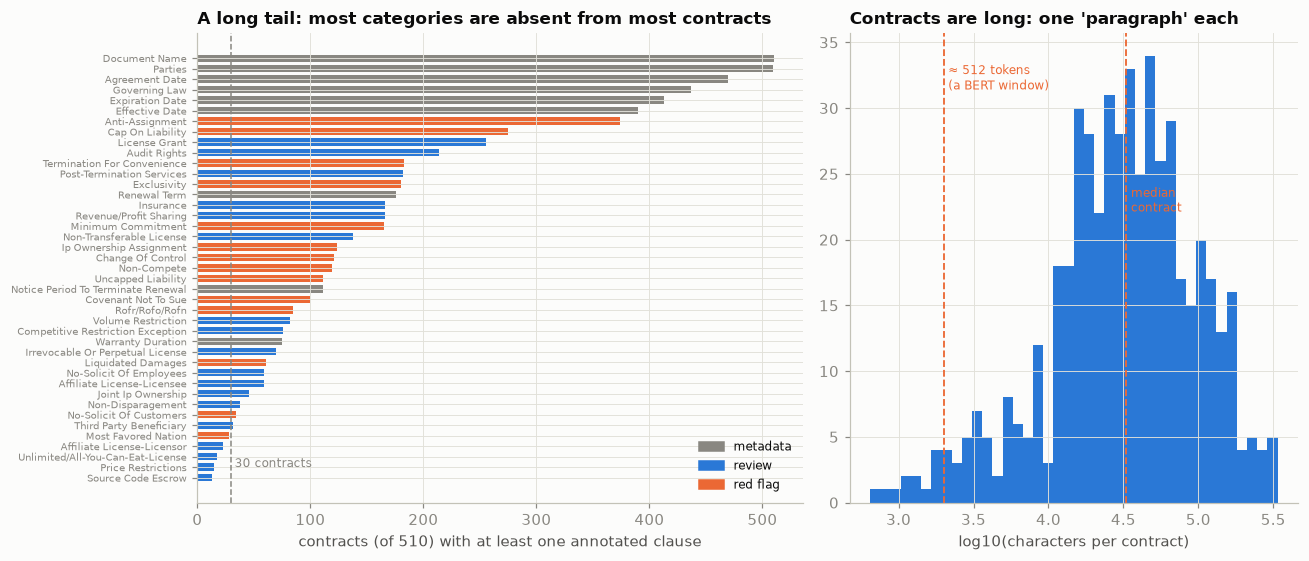

In [4]:
has = spans.groupby("category").contract_id.nunique().reindex(CATS).fillna(0).astype(int)
TIER = {c: ("red flag" if c in RED_FLAGS else "metadata" if c in
            ["Document Name", "Parties", "Agreement Date", "Effective Date", "Expiration Date", "Renewal Term",
             "Notice Period To Terminate Renewal", "Governing Law", "Warranty Duration"] else "review") for c in CATS}
TIER_COLOR = {"metadata": MUTED, "review": SERIES[0], "red flag": SERIES[1]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
order = has.sort_values()
ax.barh(range(len(order)), order.values, color=[TIER_COLOR[TIER[c]] for c in order.index], height=0.7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order.index, fontsize=6.5)
ax.axvline(30, color=MUTED, ls="--", lw=1); ax.text(33, 1, "30 contracts", color=MUTED, fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=t_) for t_, col in TIER_COLOR.items()], fontsize=8, loc="lower right"); ax.set_xlabel("contracts (of 510) with at least one annotated clause")
ax.set_title("A long tail: most categories are absent from most contracts")
ax = axes[1]
ax.hist(np.log10(contracts.n_chars), bins=40, color=SERIES[0])
for chars, lab_, h in [(2_000, "≈ 512 tokens\n(a BERT window)", 0.88), (contracts.n_chars.median(), "median\ncontract", 0.62)]:
    ax.axvline(np.log10(chars), color=SERIES[1], ls="--", lw=1.2)
    ax.text(np.log10(chars) + 0.03, ax.get_ylim()[1] * h, lab_, color=SERIES[1], fontsize=8)
ax.set_xlabel("log10(characters per contract)"); ax.set_title("Contracts are long: one 'paragraph' each")
plt.tight_layout()

pairs_with = spans[["contract_id", "category"]].drop_duplicates()
print(f"contract × category pairs with a clause: {len(pairs_with):,} of {len(contracts) * len(CATS):,} ({len(pairs_with) / (len(contracts) * len(CATS)):.0%}); "
      f"categories with fewer than 30 contracts: {', '.join(f'{c} ({n})' for c, n in has[has < 30].sort_values().items())}")
print(f"spans per (contract, category) when present: median {spans.groupby(['contract_id', 'category']).size().median():.0f}, max {spans.groupby(['contract_id', 'category']).size().max()}; "
      f"span length median {(spans.end - spans.start).median():.0f} characters, 90th percentile {(spans.end - spans.start).quantile(0.9):.0f}")

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Extraction without an LLM: chunk, retrieve, classify

*Part B · Given model · package `make_chunks`, `label_chunks`, `fit_linear` and `calibrate` unchanged; reproduce the test AUPR (C2).*

Section 2 sets the design: most answers are empty, the tail is long, and each contract is one string of 33,143 characters (median) holding clauses of about 196. So the extractor ranks *passages within a contract*, cut where clauses are, and must be able to say "not found".

**Chunking.** The README says annotators of Yes/No categories selected whole sentences, "from period to period". So the unit is a sentence-like chunk: split at blank lines and sentence ends (not after "Inc." or "Sec."), merge fragments under 40 characters forward, split anything over 1,500 characters at a semicolon. A chunk carries a category's label when it overlaps an annotated span by at least 10 characters.

In [5]:
ABBREV = {"inc", "corp", "co", "ltd", "llc", "no", "nos", "sec", "secs", "art", "mr", "mrs", "ms", "dr", "st", "vs", "v",
          "e.g", "i.e", "u.s", "u.k", "n.a", "s.a", "l.p", "etc", "approx", "jr", "sr", "p", "pp", "ex"}
SENT_END = re.compile(r"[.!?]\s+(?=[\"'“(\[]?[A-Z0-9])")
BLANK_LINE = re.compile(r"\n\s*\n")

def sentence_chunks(text: str, min_len: int = 40, max_len: int = 1500) -> list[tuple[int, int]]:
    '''Character spans of sentence-like chunks. Blank lines and sentence ends split; pieces shorter than
    min_len (headings, clause numbers) merge forward; pieces longer than max_len split at '; '.'''
    cuts = {0, len(text)} | {m.end() for m in BLANK_LINE.finditer(text)}
    for m in SENT_END.finditer(text):
        w = re.search(r"([\w.]+)$", text[max(0, m.start() - 12):m.start()])
        if not (w and (w.group(1).lower() in ABBREV or len(w.group(1)) == 1)):   # "Inc." or "A." does not end a sentence
            cuts.add(m.start() + 1)
    cuts, out, start = sorted(cuts), [], None
    for s, e in zip(cuts[:-1], cuts[1:]):
        start = s if start is None else start
        if len(text[start:e].strip()) < min_len and e < len(text):
            continue
        s0, e0 = start, e
        while s0 < e0 and text[s0].isspace(): s0 += 1
        while e0 > s0 and text[e0 - 1].isspace(): e0 -= 1
        while e0 - s0 > max_len:
            cut = text.rfind("; ", s0 + max_len // 2, s0 + max_len)
            cut = cut + 2 if cut >= 0 else (text.rfind(" ", s0 + max_len // 2, s0 + max_len) + 1 or s0 + max_len)
            out.append((s0, cut)); s0 = cut
        if e0 > s0:
            out.append((s0, e0))
        start = None
    return out

def window_chunks(text: str, size: int = 512, overlap: int = 0) -> list[tuple[int, int]]:
    '''Fixed character windows, the default in many RAG tutorials.'''
    step = size - overlap
    return [(s, min(s + size, len(text))) for s in range(0, max(len(text) - overlap, 1), step)]

def make_chunks(chunker, **kw) -> pd.DataFrame:
    rows = [(cid, k, s, e) for cid, text in zip(contracts.contract_id, contracts.text) for k, (s, e) in enumerate(chunker(text, **kw))]
    ch = pd.DataFrame(rows, columns=["contract_id", "k", "start", "end"])
    ch["relpos"] = ch.k / ch.groupby("contract_id").k.transform("size")
    return ch

def label_chunks(ch: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    '''Y[i, j] = 1 if chunk i overlaps an annotated span of category j (by ≥ 10 characters, or the whole span if shorter).
    Also returns, per span, the largest share of it that any single chunk contains.'''
    Y = np.zeros((len(ch), len(CATS)), dtype=np.int8)
    best_cover = np.zeros(len(spans))
    cat_idx = {c: j for j, c in enumerate(CATS)}
    groups = {cid: (g.index.values, g.start.values, g.end.values) for cid, g in ch.groupby("contract_id")}
    for n, (cid, cat, s, e) in enumerate(zip(spans.contract_id, spans.category, spans.start, spans.end)):
        idx, st, en = groups[cid]
        ov = np.minimum(en, e) - np.maximum(st, s)
        best_cover[n] = max(ov.max(), 0) / max(e - s, 1)
        Y[idx[ov >= min(10, e - s)], cat_idx[cat]] = 1
    return Y, best_cover

t0 = time.time()
chunks = make_chunks(sentence_chunks)
Y, cover_sent = label_chunks(chunks)
text_of = dict(zip(contracts.contract_id, contracts.text))
chunks["text"] = [text_of[c][s:e] for c, s, e in zip(chunks.contract_id, chunks.start, chunks.end)]
L = chunks.end - chunks.start
print(f"{len(chunks):,} sentence chunks in {time.time()-t0:.0f}s · median {chunks.groupby('contract_id').size().median():.0f} per contract · "
      f"length median {L.median():.0f}, 95th percentile {L.quantile(0.95):.0f} characters · {Y.any(1).mean():.1%} of chunks carry any label · "
      f"{(cover_sent >= 0.9).mean():.1%} of annotated spans sit (≥ 90 %) inside one chunk")

110,684 sentence chunks in 1s · median 134 per contract · length median 178, 95th percentile 647 characters · 10.0% of chunks carry any label · 93.5% of annotated spans sit (≥ 90 %) inside one chunk


**Split by contract, never by clause.** A deployed extractor meets contracts it has never seen, so the evaluation does too. Near-duplicate filings stay together as a family, the franchise agreements wait for Section 7, and the other 495 contracts split 60 / 20 / 20. The test set's SHA-256 fingerprint lets the CI gate refuse a changed holdout (task C4).

In [6]:
# ---- split by contract family; the held-out type is set aside as simulated new business ----
held = contracts.ctype == HELD_OUT_TYPE
fams = contracts.loc[~held, "family"].unique()
rng.shuffle(fams)
fam_size = contracts.loc[~held].groupby("family").size().reindex(fams)
cum = fam_size.cumsum() / fam_size.sum()
split_of_family = pd.Series(np.where(cum <= SPLIT[0], "train", np.where(cum <= SPLIT[0] + SPLIT[1], "valid", "test")), index=fams)
contracts["split"] = np.where(held, "held-out type", contracts.family.map(split_of_family))
chunks["split"] = chunks.contract_id.map(contracts.set_index("contract_id").split)
M = {s: (chunks.split == s).values for s in ["train", "valid", "test", "held-out type"]}

test_ids = contracts.loc[contracts.split == "test", "contract_id"]
fp_src = spans[spans.contract_id.isin(test_ids)].sort_values(["contract_id", "category", "start"])
HOLDOUT_SHA = hashlib.sha256((",".join(contracts.loc[test_ids.index, "title"]) + fp_src.to_csv(index=False)).encode()).hexdigest()
print(contracts.groupby("split").agg(contracts=("contract_id", "size"), types=("ctype", "nunique"),
                                      chunks=("contract_id", lambda s: int(chunks.contract_id.isin(s).sum())))
      .reindex(["train", "valid", "test", "held-out type"]).T.to_string())
print(f"test holdout fingerprint (SHA-256 of titles + annotations): {HOLDOUT_SHA[:16]}…")

split      train  valid   test  held-out type
contracts    297     99     99             15
types         25     21     23              1
chunks     63641  19001  21461           6581
test holdout fingerprint (SHA-256 of titles + annotations): c123abd3dad0e865…


**Retrieval with the dataset's own question.** The first baseline needs no labels: BM25 over the chunks, queried with each category's name and the description its question carries (*"Is there a restriction on the ability of a party to compete…"*).

In [7]:
TOKEN = r"(?u)\b[a-zA-Z][a-zA-Z-]+\b"

# one tokenisation pass serves both BM25 and TF-IDF: unigram + bigram counts, vocabulary restricted to the training contracts
t0 = time.time()
cv = CountVectorizer(ngram_range=(1, 2), min_df=3, token_pattern=TOKEN, dtype=np.float32)
COUNTS = cv.fit_transform(chunks.text).tocsc()
train_df = np.asarray((COUNTS[M["train"]] > 0).sum(0)).ravel()
vocab_keep = np.argsort(-train_df)[:MAX_FEATURES]
vocab_keep = np.sort(vocab_keep[train_df[vocab_keep] >= 3])
COUNTS = COUNTS[:, vocab_keep].tocsr()
VOCAB = cv.get_feature_names_out()[vocab_keep]
t_tok = time.time() - t0

def bm25_matrix(counts, fit_rows, k1=1.5, b=0.75):
    '''BM25 weights for every chunk as one sparse matrix, so scoring all chunks against all queries is a single product.'''
    n = fit_rows.sum()
    df = np.asarray((counts[fit_rows] > 0).sum(0)).ravel()
    idf = np.log((n - df + 0.5) / (df + 0.5) + 1).astype(np.float32)
    dl = np.asarray(counts.sum(1)).ravel(); avgdl = dl[fit_rows].mean()
    W = counts.copy()
    rows = np.repeat(np.arange(W.shape[0]), np.diff(W.indptr))
    W.data = W.data * (k1 + 1) / (W.data + k1 * (1 - b + b * dl[rows] / avgdl)) * idf[W.indices]
    return W

def query_matrix(queries):
    an = cv.build_analyzer(); col = {t: i for i, t in enumerate(VOCAB)}
    Q = np.zeros((len(queries), len(VOCAB)), dtype=np.float32)
    for i, q in enumerate(queries):
        for t in set(an(q)):
            if t in col: Q[i, col[t]] = 1
    return sp.csr_matrix(Q)

def details(q: str) -> str:
    return q.split("Details:")[-1].strip()

QUERY_DATASET = [f"{c} {details(q)}" for c, q in zip(questions.category, questions.question)]   # what the dataset itself says
W_BM25 = bm25_matrix(COUNTS, M["train"])
S_bm25 = np.asarray((W_BM25 @ query_matrix(QUERY_DATASET).T).todense())
print(f"{COUNTS.shape[0]:,} chunks × {COUNTS.shape[1]:,} terms (unigrams + bigrams seen in ≥ 3 training chunks) in {t_tok:.0f}s · "
      f"BM25 scores for 41 category queries in {time.time()-t0-t_tok:.1f}s")

110,684 chunks × 94,542 terms (unigrams + bigrams seen in ≥ 3 training chunks) in 9s · BM25 scores for 41 category queries in 0.4s


**A linear classifier per category.** TF-IDF over unigrams and bigrams plus four position features (parties and dates sit at the top). One linear SVM per category trains on every labelled chunk and a fixed 25 % of the rest. Scores are calibrated on validation contracts (Platt scaling) so that 41 models can be ranked together in Section 6.

Metrics per category, then averaged: **AUPR** over chunks (the CUAD paper's headline metric; it scores spans, so numbers are not comparable); **P@3**, precision of three highlights per contract × category pair, clause present or not; **R@3**, the share of pairs with a clause where a highlight is a clause chunk.

In [8]:
def eval_scores(S, mask, k=K_HIGHLIGHTS, cats=CATS):
    '''Per category, on the contracts in `mask`: AUPR over chunks (the CUAD paper's headline metric, here at chunk level),
    precision@k over every contract × category pair (k highlights each, clause present or not), and recall@k = share of
    pairs with a clause in which at least one of the k highlights is a clause chunk.'''
    rows, cid = [], chunks.contract_id.values[mask]
    for c in cats:
        j = CATS.index(c)
        y, s = Y[mask, j], S[mask, j]
        d = pd.DataFrame({"cid": cid, "s": s, "y": y}).sort_values(["cid", "s"], ascending=[True, False])
        top = d.groupby("cid").head(k).groupby("cid").y.agg(["sum", "size"])
        present = d.groupby("cid").y.max()
        rows.append({"category": c, "contracts with clause": int(present.sum()),
                     "AUPR": average_precision_score(y, s) if y.sum() else np.nan,
                     f"P@{k}": top["sum"].sum() / top["size"].sum(),
                     f"R@{k}": (top["sum"] > 0)[present > 0].mean() if present.sum() else np.nan})
    return pd.DataFrame(rows).set_index("category")

def fit_linear(X, train_mask, cats=CATS, C=0.3):
    '''One linear SVM per category on the training chunks: every labelled chunk plus a fixed NEG_SAMPLE of the rest.'''
    keep = train_mask & (Y.any(1) | (np.random.default_rng(SEED).random(len(Y)) < NEG_SAMPLE))
    S = np.zeros((X.shape[0], len(CATS)), dtype=np.float32)
    for c in cats:
        j = CATS.index(c)
        if Y[keep, j].sum():
            S[:, j] = LinearSVC(C=C, class_weight="balanced", tol=1e-2, random_state=SEED).fit(X[keep], Y[keep, j]).decision_function(X)
    return S, int(keep.sum())

def calibrate(S, fit_mask):
    '''Platt scaling per category on the validation chunks (two parameters, Newton steps), so that scores from
    41 different models can be ranked against each other.'''
    P = np.zeros_like(S)
    for j in range(S.shape[1]):
        y, s, a, b = Y[fit_mask, j], S[fit_mask, j], 1.0, 0.0
        for _ in range(25):
            p = 1 / (1 + np.exp(-(a * s + b))); w = p * (1 - p)
            g = np.array([((p - y) * s).sum() + 1e-3 * a, (p - y).sum()])
            H = np.array([[(w * s * s).sum() + 1e-3, (w * s).sum()], [(w * s).sum(), w.sum() + 1e-9]])
            a, b = np.array([a, b]) - np.linalg.solve(H, g)
        P[:, j] = 1 / (1 + np.exp(-(a * S[:, j] + b)))
    return P

t0 = time.time()
tfidf = TfidfTransformer(sublinear_tf=True).fit(COUNTS[M["train"]])
r = chunks.relpos.values
POS = sp.csr_matrix(np.c_[r, r < 0.02, r < 0.1, r > 0.9].astype(np.float32))          # where in the contract the chunk sits
X_text = sp.hstack([tfidf.transform(COUNTS), POS]).tocsr()
S_clf, n_fit = fit_linear(X_text, M["train"])
print(f"41 linear SVMs on {n_fit:,} training chunks ({X_text.shape[1]:,} features) in {time.time()-t0:.0f}s")

res = {("BM25, dataset question", "test"): eval_scores(S_bm25, M["test"]),
       ("TF-IDF + linear SVM", "validation"): eval_scores(S_clf, M["valid"]),
       ("TF-IDF + linear SVM", "test"): eval_scores(S_clf, M["test"])}
by_tier = pd.concat({k: v.drop(columns="contracts with clause").groupby(v.index.map(TIER)).mean() for k, v in res.items()}, names=["method", "split", "tier"])
overall = pd.concat({k: v.drop(columns="contracts with clause").mean().to_frame("all 41").T for k, v in res.items()}, names=["method", "split", "tier"])
display(pd.concat([overall, by_tier]).sort_index().unstack("tier").swaplevel(axis=1).sort_index(axis=1)
        .reindex(columns=["all 41", "metadata", "review", "red flag"], level=0).style.format("{:.3f}"))

def fast_ap(y, s):
    o = np.argsort(-s, kind="stable"); y = y[o]
    tp = np.cumsum(y); return float((tp[y == 1] / (np.flatnonzero(y) + 1)).sum() / max(y.sum(), 1))

def boot_macro_ap(groups, S, n=200, cats=range(len(CATS)), seed=SEED):
    '''Macro AUPR over `cats` for n bootstrap resamples of whole contracts ({contract: chunk rows}).'''
    ids_, rb, out = np.array(list(groups)), np.random.default_rng(seed), []
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rb.choice(ids_, len(ids_))])
        out.append([fast_ap(Y[idx, j], S[idx, j]) if Y[idx, j].any() else np.nan for j in cats])
    return np.array(out)

# the only time axis in the data: filing year. Does the extractor do worse on recent filings?
era = chunks.contract_id.map(contracts.set_index("contract_id").year).values
CID = chunks.contract_id.values
era_ap = {}
for name, m in [(f"filed before {FILING_YEAR_SPLIT}", M["test"] & (era < FILING_YEAR_SPLIT)),
                (f"filed {FILING_YEAR_SPLIT} or later", M["test"] & (era >= FILING_YEAR_SPLIT))]:
    e = eval_scores(S_clf, m)
    era_ap[name] = np.nanmean(boot_macro_ap({c: np.flatnonzero(m & (CID == c)) for c in np.unique(CID[m])}, S_clf), axis=1)
    print(f"test contracts {name}: {len(np.unique(CID[m]))} · macro AUPR {e.AUPR.mean():.3f} · R@{K_HIGHLIGHTS} {e[f'R@{K_HIGHLIGHTS}'].mean():.3f}")
lo_, hi_ = np.percentile(np.subtract(*list(era_ap.values())[::-1]), [2.5, 97.5])
print(f"difference (later − earlier), 95 % bootstrap interval over contracts: [{lo_:+.3f}, {hi_:+.3f}]")

41 linear SVMs on 20,676 training chunks (94,546 features) in 10s


test contracts filed before 2010: 35 · macro AUPR 0.494 · R@3 0.859


test contracts filed 2010 or later: 58 · macro AUPR 0.527 · R@3 0.909
difference (later − earlier), 95 % bootstrap interval over contracts: [-0.059, +0.086]


First, the table. Queried with the dataset's own descriptions, BM25 reaches a macro AUPR of 0.077. The classifier reaches 0.489 on test (0.520 on validation) and finds a clause chunk in its top three for 89 % of the pairs that have one; P@3 is 0.127 because most pairs have nothing to find. Metadata is easiest (0.690), the "review" tier hardest (0.385).

Filing year, the only time axis, shows no degradation (0.527 for test contracts filed from 2010, 0.494 before; the difference's interval, −0.059 to +0.086, spans zero): hence a split by contract family, not time, and a drift test by contract type (Section 7).

## 4 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test, including the chunker's clause-cut limit.*

Each trap below makes a number look better than it is. Each is measured.

**Trap 1 — splitting by clause instead of by contract.** Shuffle chunks into train and test and the model learns from other sentences of the contracts it is tested on. To isolate that, both models are scored on the same half of every test contract's chunks and trained on equally many chunks; the clause split's training set simply includes the other half of those contracts.

In [9]:
# Trap 1: the same evaluation chunks (half of every test contract), two training sets of the same size
u = np.random.default_rng(SEED + 1).random(len(Y))
EVAL = M["test"] & (u < 0.5)
pool = np.flatnonzero((M["train"] | M["test"]) & ~EVAL)
np.random.default_rng(SEED + 2).shuffle(pool)
naive_train = np.zeros(len(Y), bool); naive_train[pool[:M["train"].sum()]] = True      # clause-level split: siblings of EVAL leak in
tfidf_n = TfidfTransformer(sublinear_tf=True).fit(COUNTS[naive_train])
X_naive = sp.hstack([tfidf_n.transform(COUNTS), POS]).tocsr()
t0 = time.time()
S_naive, _ = fit_linear(X_naive, naive_train, cats=RED_FLAGS)
trap1 = pd.DataFrame({"split by clause ⚠": eval_scores(S_naive, EVAL, cats=RED_FLAGS).AUPR,
                      "split by contract": eval_scores(S_clf, EVAL, cats=RED_FLAGS).AUPR})
trap1["inflation"] = trap1.iloc[:, 0] - trap1.iloc[:, 1]
spc = spans.groupby("category").size() / has
trap1["spans per contract"] = spc.reindex(trap1.index)
print(f"{(naive_train & M['test']).sum():,} of the clause-split training chunks come from the evaluated contracts ({time.time()-t0:.0f}s)")
print(f"macro AUPR on the same {EVAL.sum():,} evaluation chunks, 14 red-flag categories: split by clause {trap1.iloc[:, 0].mean():.3f} · "
      f"split by contract {trap1.iloc[:, 1].mean():.3f} · categories inflated: {(trap1.inflation > 0).sum()} of 14 · "
      f"correlation of inflation with spans per contract: {trap1.inflation.corr(trap1['spans per contract']):.2f}")
# is the gap more than noise? paired bootstrap over the evaluated contracts, same resample for both models
ev_groups = {c: np.flatnonzero(EVAL & (CID == c)) for c in np.unique(CID[EVAL])}
rf_idx = [CATS.index(c) for c in RED_FLAGS]
gap = np.nanmean(boot_macro_ap(ev_groups, S_naive, n=300, cats=rf_idx) - boot_macro_ap(ev_groups, S_clf, n=300, cats=rf_idx), axis=1)
# the leak channel itself: evaluation chunks whose normalised text also appears among the training chunks
norm_txt = chunks.text.str.lower().str.replace(r"\s+", " ", regex=True).values
twin = lambda train_mask: np.isin(norm_txt[EVAL], np.unique(norm_txt[train_mask])).mean()
print(f"gap +{trap1.inflation.mean():.3f}, 95 % interval [{np.percentile(gap, 2.5):+.3f}, {np.percentile(gap, 97.5):+.3f}] "
      f"(paired bootstrap over {len(ev_groups)} contracts) · evaluation chunks with an exact twin in training: "
      f"clause split {twin(naive_train):.1%}, contract split {twin(M['train']):.1%}")
trap1.sort_values("inflation", ascending=False).round(3)

9,129 of the clause-split training chunks come from the evaluated contracts (3s)
macro AUPR on the same 10,836 evaluation chunks, 14 red-flag categories: split by clause 0.559 · split by contract 0.522 · categories inflated: 8 of 14 · correlation of inflation with spans per contract: 0.34


gap +0.037, 95 % interval [-0.021, +0.090] (paired bootstrap over 99 contracts) · evaluation chunks with an exact twin in training: clause split 4.7%, contract split 1.3%


,split by clause ⚠,split by contract,inflation,spans per contract
category,,,,
No-Solicit Of Customers,0.475,0.122,0.353,1.706
Rofr/Rofo/Rofn,0.762,0.583,0.180,4.318
Liquidated Damages,0.546,0.367,0.179,1.984
Non-Compete,0.443,0.353,0.091,2.176
Minimum Commitment,0.344,0.282,0.062,2.570
Uncapped Liability,0.577,0.533,0.045,1.505
Ip Ownership Assignment,0.693,0.669,0.024,2.565
Anti-Assignment,0.861,0.860,0.001,1.749
Change Of Control,0.176,0.177,-0.001,2.091


The clause split scores 0.037 higher on the 14 red-flag categories (0.559 against 0.522), but the paired bootstrap interval, −0.021 to +0.090, includes zero: at this test size the leak is **not demonstrated**. Per-category swings go both ways (No-Solicit of Customers +0.35 on 5 test contracts, MFN −0.33), as noise does. The channel exists (4.7 % of evaluation chunks have an exact twin in the clause-split training set, 1.3 % under the contract split); its effect here is within noise. The rule stands for another reason: only a contract split measures what deployment faces, an unseen contract. C1 retests the leak on all 41 categories and several seeds.

**Trap 2 — the long tail.** One average hides which categories are weak and how little the test set knows about rare ones. The bootstrap resamples test contracts, not chunks.

pooled ('micro') AUPR over all chunk × category pairs: 0.606 · macro over 41 categories: 0.489 · 11 tail categories (< 60 contracts): 0.312
median width of the 90 % interval: head 0.21 · tail 0.37


,test contracts with clause,AUPR,90% lo,90% hi
Source Code Escrow,2,0.49,0.27,0.64
Price Restrictions,3,0.06,0.01,0.24
Unlimited/All-You-Can-Eat-License,3,0.19,0.11,0.35
Affiliate License-Licensor,4,0.12,0.07,0.34
No-Solicit Of Customers,5,0.14,0.02,0.53
Non-Disparagement,5,0.31,0.14,0.60


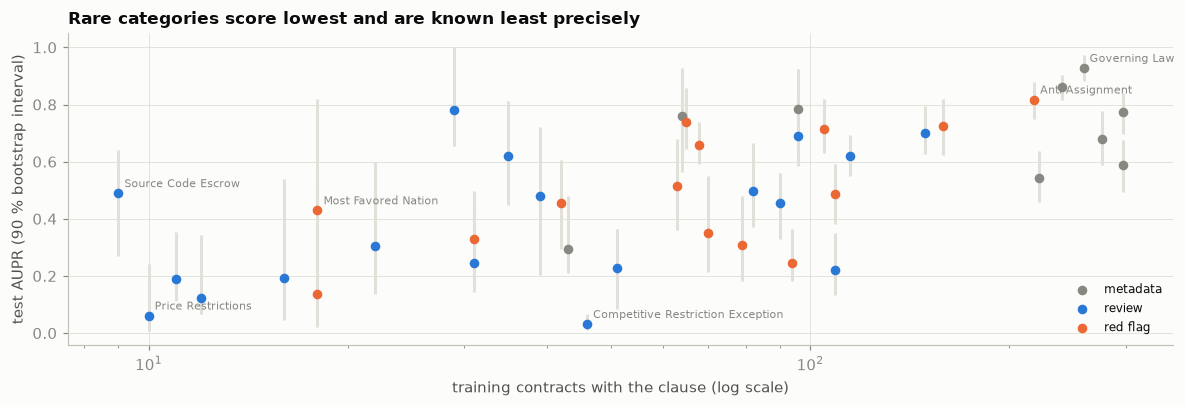

In [10]:
P_clf = calibrate(S_clf, M["valid"])
te = M["test"]
aupr = res[("TF-IDF + linear SVM", "test")].AUPR
micro = average_precision_score(Y[te].ravel(), P_clf[te].ravel())
n_train = pd.DataFrame(Y[M["train"]], columns=CATS).groupby(chunks.contract_id.values[M["train"]]).max().sum()
n_test = pd.DataFrame(Y[te], columns=CATS).groupby(chunks.contract_id.values[te]).max().sum()
TAIL = has[has < 60].index.tolist()

# bootstrap over test contracts: how certain is each per-category number?
cid_te = chunks.contract_id.values
rows_of = {c: np.flatnonzero((cid_te == c) & te) for c in np.unique(cid_te[te])}
ids = np.array(list(rows_of)); rngb = np.random.default_rng(SEED)
boot = np.full((200, len(CATS)), np.nan)
for b in range(200):
    idx = np.concatenate([rows_of[i] for i in rngb.choice(ids, len(ids))])
    for j in range(len(CATS)):
        if Y[idx, j].any():
            boot[b, j] = fast_ap(Y[idx, j], S_clf[idx, j])
ci = pd.DataFrame(np.nanpercentile(boot, [5, 95], axis=0).T, index=CATS, columns=["lo", "hi"])

fig, ax = plt.subplots(figsize=(11, 3.8))
x = n_train.reindex(CATS).values
ax.errorbar(x, aupr.values, yerr=[aupr.values - ci.lo.values, ci.hi.values - aupr.values], fmt="none", ecolor=GRID, elinewidth=2)
for t_, col in TIER_COLOR.items():
    m_ = np.array([TIER[c] == t_ for c in CATS])
    ax.scatter(x[m_], aupr.values[m_], color=col, s=28, label=t_, zorder=3)
for c in ["Source Code Escrow", "Price Restrictions", "Most Favored Nation", "Competitive Restriction Exception", "Governing Law", "Anti-Assignment"]:
    ax.annotate(c, (n_train[c], aupr[c]), xytext=(4, 4), textcoords="offset points", fontsize=7, color=MUTED)
ax.set_xscale("log"); ax.set_xlabel("training contracts with the clause (log scale)"); ax.set_ylabel("test AUPR (90 % bootstrap interval)")
ax.set_title("Rare categories score lowest and are known least precisely"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
print(f"pooled ('micro') AUPR over all chunk × category pairs: {micro:.3f} · macro over 41 categories: {aupr.mean():.3f} · "
      f"{len(TAIL)} tail categories (< 60 contracts): {aupr[TAIL].mean():.3f}")
print(f"median width of the 90 % interval: head {(ci.hi - ci.lo).drop(TAIL).median():.2f} · tail {(ci.hi - ci.lo)[TAIL].median():.2f}")
display(pd.DataFrame({"test contracts with clause": n_test, "AUPR": aupr, "90% lo": ci.lo, "90% hi": ci.hi}).loc[TAIL]
        .sort_values("test contracts with clause").head(6).style.format({"AUPR": "{:.2f}", "90% lo": "{:.2f}", "90% hi": "{:.2f}"}))

Pooled over all chunk × category pairs, AUPR is 0.606, because frequent categories dominate. The macro average is 0.489; the 11 categories found in fewer than 60 contracts average 0.312. Source Code Escrow appears in 2 test contracts, Price Restrictions in 3: a 90 % interval of 0.01–0.24 is not a score. Report macro and tail separately and gate only categories with enough test contracts (C4).

**Trap 3 — "no answer" is most of the answers.** SQuAD-style evaluation often scores only questions with an answer; here, a third of them.

In [11]:
tops = []
for j, c in enumerate(CATS):
    d = pd.DataFrame({"cid": cid_te[te], "s": S_clf[te, j], "y": Y[te, j], "p": P_clf[te, j]}).sort_values(["cid", "s"], ascending=[True, False])
    t_ = d.groupby("cid").head(K_HIGHLIGHTS).groupby("cid").agg(hits=("y", "sum"), n=("y", "size"), pmax=("p", "max"))
    t_["present"], t_["category"] = d.groupby("cid").y.max(), c
    tops.append(t_)
tops = pd.concat(tops)
hasans = tops[tops.present == 1]
red = tops[tops.category.isin(RED_FLAGS)]
print(f"precision@{K_HIGHLIGHTS} on pairs where the clause exists (SQuAD 'HasAns' style) ⚠: {hasans.hits.sum() / hasans.n.sum():.3f} · "
      f"on every contract × category pair: {tops.hits.sum() / tops.n.sum():.3f} · "
      f"share of all highlights spent on absent clauses: {tops[tops.present == 0].n.sum() / tops.n.sum():.0%}")
pres_tbl = pd.DataFrame({thr: {"absent red flags flagged (false alarm)": (red[red.present == 0].pmax >= thr).mean(),
                               "present red flags flagged": (red[red.present == 1].pmax >= thr).mean()} for thr in [0.3, 0.5, 0.7]}).T
pres_tbl.index.name = "calibrated threshold"
print(f"red-flag presence from the best chunk's probability: AUPR {average_precision_score(red.present, red.pmax):.3f} (base rate {red.present.mean():.2f})")
pres_tbl.style.format("{:.1%}")

precision@3 on pairs where the clause exists (SQuAD 'HasAns' style) ⚠: 0.420 · on every contract × category pair: 0.127 · share of all highlights spent on absent clauses: 70%
red-flag presence from the best chunk's probability: AUPR 0.880 (base rate 0.26)


,absent red flags flagged (false alarm),present red flags flagged
calibrated threshold,,
0.300000,5.8%,77.7%
0.500000,3.9%,67.7%
0.700000,2.4%,60.7%


Scored only where a clause exists, P@3 is 0.420; over every pair it is 0.127, and 70 % of highlights land on clauses that are not there. The best chunk's probability separates present from absent red flags well (AUPR 0.880, base rate 0.26), yet at a 0.5 threshold a third of present red flags go unflagged. The assistant should say "not found in the highlights", never "absent".

**Trap 4 — chunks that straddle a clause.** RAG tutorials often cut fixed windows, blind to where a clause ends. Below: chunkers compared, then the extractor retrained on 512-character windows and scored two ways.

In [12]:
def para_chunks(text: str) -> list[tuple[int, int]]:
    out, pos = [], 0
    for m in BLANK_LINE.finditer(text):
        if m.start() > pos: out.append((pos, m.start()))
        pos = m.end()
    return out + ([(pos, len(text))] if pos < len(text) else [])

def complete_recall(ch, S, mask, cats=RED_FLAGS, k=K_HIGHLIGHTS):
    '''Per (contract, category) with a clause: does a top-k highlight touch a clause (≥ 10 characters), and does one
    highlight show a whole clause (≥ 90 % of its characters)?'''
    any_hit, whole = [], []
    by_pair = {key: g for key, g in spans.groupby(["contract_id", "category"])}
    for c in cats:
        j = CATS.index(c)
        d = pd.DataFrame({"cid": ch.contract_id.values[mask], "s": S[mask, j], "st": ch.start.values[mask], "en": ch.end.values[mask]})
        for cid_, g in d.sort_values(["cid", "s"], ascending=[True, False]).groupby("cid").head(k).groupby("cid"):
            if (cid_, c) in by_pair:
                ss = by_pair[(cid_, c)]
                ov = np.minimum(g.en.values[:, None], ss.end.values) - np.maximum(g.st.values[:, None], ss.start.values)
                L = (ss.end - ss.start).values
                any_hit.append((ov >= np.minimum(10, L)).any()); whole.append((ov >= 0.9 * L).any())
    return np.mean(any_hit), np.mean(whole)

geo = {}
for name, fn, kw in [("sentences (this notebook)", sentence_chunks, {}), ("paragraphs (blank lines)", para_chunks, {}),
                     ("512-character windows", window_chunks, {"size": 512}),
                     ("512-character windows, 128 overlap", window_chunks, {"size": 512, "overlap": 128}),
                     ("2,000-character windows", window_chunks, {"size": 2000})]:
    ch_ = chunks if fn is sentence_chunks else make_chunks(fn, **kw)
    Yc, cov = (Y, cover_sent) if fn is sentence_chunks else label_chunks(ch_)
    geo[name] = {"chunks": len(ch_), "median characters": (ch_.end - ch_.start).median(), "99th percentile": (ch_.end - ch_.start).quantile(0.99),
                 "clauses cut (no chunk holds 90 %)": (cov < 0.9).mean(),
                 "chunks labelled positive": Yc.any(1).mean()}
    if kw.get("size") == 512 and not kw.get("overlap"):
        win, Y_win = ch_, Yc

# train the same extractor on 512-character windows (red-flag categories) and compare what the lawyer is shown
t0 = time.time()
win_text = [text_of[c][s:e] for c, s, e in zip(win.contract_id, win.start, win.end)]
win_split = win.contract_id.map(contracts.set_index("contract_id").split).values
C_win = sp.csr_matrix(cv.transform(win_text))[:, vocab_keep]
rw = win.relpos.values
X_win = sp.hstack([TfidfTransformer(sublinear_tf=True).fit(C_win[win_split == "train"]).transform(C_win),
                   sp.csr_matrix(np.c_[rw, rw < 0.02, rw < 0.1, rw > 0.9].astype(np.float32))]).tocsr()
Y_main = Y; Y = Y_win                                   # fit_linear reads the global label matrix
S_win, _ = fit_linear(X_win, win_split == "train", cats=RED_FLAGS)
Y = Y_main
a_s, w_s = complete_recall(chunks, S_clf, M["test"])
a_w, w_w = complete_recall(win, S_win, win_split == "test")
display(pd.DataFrame(geo).T.style.format({"chunks": "{:,.0f}", "median characters": "{:,.0f}", "99th percentile": "{:,.0f}", "clauses cut (no chunk holds 90 %)": "{:.1%}",
                                          "chunks labelled positive": "{:.1%}"}))
print(f"red-flag recall@{K_HIGHLIGHTS} on test contracts ({time.time()-t0:.0f}s) — counting any overlap ⚠: sentences {a_s:.3f}, 512-char windows {a_w:.3f} · "
      f"counting only a highlight that shows ≥ 90 % of the clause: sentences {w_s:.3f}, 512-char windows {w_w:.3f}")

,chunks,median characters,99th percentile,clauses cut (no chunk holds 90 %),chunks labelled positive
sentences (this notebook),"110,684",178,"1,185",6.5%,10.0%
paragraphs (blank lines),"74,435",139,"3,458",3.1%,10.5%
512-character windows,"52,614",512,512,36.5%,22.0%
"512-character windows, 128 overlap","69,891",512,512,25.9%,22.2%
"2,000-character windows","13,661","2,000","2,000",10.5%,42.5%


red-flag recall@3 on test contracts (11s) — counting any overlap ⚠: sentences 0.930, 512-char windows 0.925 · counting only a highlight that shows ≥ 90 % of the clause: sentences 0.880, 512-char windows 0.535


Fixed 512-character windows cut 36.5 % of annotated clauses (25.9 % with overlap); sentences cut 6.5 %. Scored by any overlap, windows look as good as sentences (recall@3 0.925 against 0.930); scored as the lawyer reads, one highlight showing 90 % of the clause, they fall to 0.535 against 0.880. At 2,000 characters, 42.5 % of chunks carry a label, four times the sentence rate.

## 5 · The knowledge layer: clause taxonomy, party–obligation graph, and their worth

*Part B · Given model · package the taxonomy, `shacl_violations`, `zs` and `obligation_graph`; E1 extends the ablation, E2 the obligor shape.*

The taxonomy writes down what the dataset knows, for a pipeline to use and check (Sessions 07–08): 41 categories with descriptions and README groups, a tier, relations read from the README (an exception *to* a restriction, licences that *refine* a grant, dates that *depend on* dates) and a reviewer's lexicon. SHACL validates the taxonomy, then the annotations against it.

In [13]:
LEXICON = {   # the team's clause lexicon: phrases a reviewer searches for. An assumption, versioned with the KB (task E1)
    "Document Name": ["agreement", "this agreement", "contract", "exhibit"],
    "Parties": ["by and between", "entered into by", "between", "corporation", "limited liability company", "hereinafter", "party", "parties"],
    "Agreement Date": ["dated as of", "made and entered into", "day of", "as of the date", "dated"],
    "Effective Date": ["effective date", "effective as of", "shall become effective", "commencement date", "effective upon"],
    "Expiration Date": ["initial term", "expire", "expiration", "remain in effect", "remain in full force", "years from", "term of this agreement"],
    "Renewal Term": ["renew", "renewal", "automatically renewed", "successive", "additional term", "extend the term"],
    "Notice Period To Terminate Renewal": ["notice of non-renewal", "prior to the expiration", "days prior", "not to renew", "written notice", "elect not to renew"],
    "Governing Law": ["governed by", "laws of the state", "construed in accordance", "governing law", "without regard to conflicts"],
    "Most Favored Nation": ["most favored", "most favoured", "no less favorable", "more favorable terms", "lower price", "better terms", "terms offered to any other"],
    "Non-Compete": ["compete", "competing", "competitive", "non-compete", "shall not engage", "directly or indirectly", "competitor"],
    "Exclusivity": ["exclusive", "exclusively", "sole and exclusive", "exclusive distributor", "exclusive right", "requirements", "shall not appoint"],
    "No-Solicit Of Customers": ["solicit", "customers", "clients", "induce", "divert", "entice", "accounts"],
    "Competitive Restriction Exception": ["notwithstanding", "except", "shall not apply", "shall not prevent", "provided however", "nothing in this", "exception"],
    "No-Solicit Of Employees": ["solicit", "hire", "employ", "employees", "personnel", "recruit"],
    "Non-Disparagement": ["disparage", "disparaging", "derogatory", "negative statements", "reputation"],
    "Termination For Convenience": ["terminate this agreement", "for any reason", "without cause", "for convenience", "at any time", "with or without cause"],
    "Rofr/Rofo/Rofn": ["right of first refusal", "first refusal", "right of first offer", "first negotiation", "right to match", "first option"],
    "Change Of Control": ["change of control", "change in control", "merger", "acquisition", "acquired", "controlling interest", "substantially all", "voting securities"],
    "Anti-Assignment": ["assign", "assignment", "transfer", "prior written consent", "delegate", "successors and assigns"],
    "Revenue/Profit Sharing": ["royalty", "royalties", "revenue share", "profits", "percentage of", "net sales", "commission", "share of revenue"],
    "Price Restrictions": ["price", "pricing", "shall not increase", "price increase", "price adjustment", "fixed price", "price protection"],
    "Minimum Commitment": ["minimum", "at least", "minimum purchase", "minimum order", "minimum quantity", "shall purchase", "annual minimum", "shortfall"],
    "Volume Restriction": ["volume", "exceed", "in excess of", "maximum", "threshold", "additional fee", "usage"],
    "Ip Ownership Assignment": ["hereby assigns", "shall own", "ownership", "work made for hire", "right title and interest", "vest", "sole property"],
    "Joint Ip Ownership": ["jointly owned", "joint ownership", "co-owned", "jointly", "joint inventions", "owned jointly"],
    "License Grant": ["hereby grants", "grants to", "license", "licence", "right to use", "sublicense"],
    "Non-Transferable License": ["non-transferable", "nontransferable", "non-assignable", "non-sublicensable", "may not sublicense", "personal"],
    "Affiliate License-Licensor": ["affiliates", "licensor and its affiliates", "its affiliates", "affiliate"],
    "Affiliate License-Licensee": ["affiliates", "licensee and its affiliates", "subsidiaries", "affiliate"],
    "Unlimited/All-You-Can-Eat-License": ["unlimited", "enterprise", "any number", "unlimited number", "all you can eat", "without limitation"],
    "Irrevocable Or Perpetual License": ["irrevocable", "perpetual", "fully paid", "royalty-free", "in perpetuity"],
    "Source Code Escrow": ["escrow", "source code", "escrow agent", "release condition", "deposit"],
    "Post-Termination Services": ["after termination", "following termination", "upon termination", "survive", "transition", "wind down", "sell off"],
    "Audit Rights": ["audit", "inspect", "examine", "books and records", "records", "accountant"],
    "Uncapped Liability": ["shall not apply", "gross negligence", "willful misconduct", "indemnification obligations", "breach of confidentiality", "unlimited liability", "exclusions"],
    "Cap On Liability": ["in no event", "liability", "shall not exceed", "aggregate liability", "limitation of liability", "consequential", "maximum"],
    "Liquidated Damages": ["liquidated damages", "termination fee", "penalty", "break fee", "liquidated"],
    "Warranty Duration": ["warranty", "warrants", "warranty period", "months from", "free from defects"],
    "Insurance": ["insurance", "insured", "policy", "coverage", "additional insured", "certificate of insurance"],
    "Covenant Not To Sue": ["not to sue", "contest", "challenge", "validity", "shall not challenge", "covenant not to", "claim"],
    "Third Party Beneficiary": ["third party beneficiary", "third-party beneficiaries", "intended beneficiary", "enforce", "no third party"],
}

In [14]:
# ---- the clause taxonomy as a small RDF graph: categories, README groups and descriptions, tiers, relations, lexicon ----
CR = Namespace("https://ari3217.example/contract-review#")
README_CATS = re.findall(r"Category:\s*(.+?)\n\s*Description:\s*(.+?)\n\s*Answer Format:\s*(.+?)\n\s*Group:\s*(.+?)\n",
                         README.split("CATEGORY LIST")[1].split("=====")[0])
assert len(README_CATS) == len(CATS) == 41
norm_ws = lambda s: re.sub(r"\s+", " ", s).strip()
slug = lambda c: re.sub(r"[^A-Za-z0-9]+", "_", c).strip("_")
RELATIONS = [  # (subject, predicate, object): read from the README's category descriptions and group notes
    *[("Competitive Restriction Exception", "exceptionTo", c) for c in ["Non-Compete", "Exclusivity", "No-Solicit Of Customers"]],
    *[(c, "refines", "License Grant") for c in ["Non-Transferable License", "Affiliate License-Licensor", "Affiliate License-Licensee",
                                                "Irrevocable Or Perpetual License"]],
    ("Uncapped Liability", "contrastsWith", "Cap On Liability"), ("Change Of Control", "relatedTo", "Anti-Assignment"),
    ("Effective Date", "dependsOn", "Agreement Date"), ("Expiration Date", "dependsOn", "Effective Date"),
    ("Renewal Term", "dependsOn", "Expiration Date"), ("Notice Period To Terminate Renewal", "dependsOn", "Renewal Term"),
]
kb = Graph(); kb.bind("cr", CR); kb.bind("skos", SKOS)
for cat, (rname, desc, fmt, grp) in zip(CATS, README_CATS):
    assert norm_ws(desc) == norm_ws(details(questions.set_index("category").question[cat])), cat   # README ↔ JSON alignment
    u = CR[slug(cat)]
    kb.add((u, RDF.type, CR.ClauseCategory)); kb.add((u, SKOS.prefLabel, Literal(cat)))
    if norm_ws(rname).lower() != cat.lower():
        kb.add((u, SKOS.altLabel, Literal(norm_ws(rname))))                                   # the README's spelling
    kb.add((u, SKOS.definition, Literal(norm_ws(desc)))); kb.add((u, CR.answerFormat, Literal(norm_ws(fmt))))
    kb.add((u, CR.tier, Literal(TIER[cat])))
    if grp.strip() != "-":
        kb.add((u, CR.inGroup, CR[f"group{grp.strip()}"])); kb.add((CR[f"group{grp.strip()}"], RDF.type, CR.Group))
    for kw in LEXICON[cat]:
        kb.add((u, CR.keyword, Literal(kw)))
for s_, p_, o_ in RELATIONS:
    kb.add((CR[slug(s_)], CR[p_], CR[slug(o_)]))

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix cr: <https://ari3217.example/contract-review#> .
@prefix skos: <http://www.w3.org/2004/02/skos/core#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
cr:CategoryShape a sh:NodeShape ; sh:targetClass cr:ClauseCategory ;
  sh:property [ sh:path skos:prefLabel ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path skos:definition ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cr:tier ; sh:minCount 1 ; sh:maxCount 1 ; sh:in ( "metadata" "review" "red flag" ) ] ;
  sh:property [ sh:path cr:inGroup ; sh:maxCount 1 ; sh:class cr:Group ] ;
  sh:property [ sh:path cr:keyword ; sh:minCount 3 ] .
cr:ContractShape a sh:NodeShape ; sh:targetClass cr:Contract ;
  sh:sparql [ sh:message "Competitive Restriction Exception without the restriction it is an exception to" ;
    sh:select \"\"\"PREFIX cr: <https://ari3217.example/contract-review#>
      SELECT $this WHERE { $this cr:hasClause cr:Competitive_Restriction_Exception .
        FILTER NOT EXISTS { $this cr:hasClause ?r . cr:Competitive_Restriction_Exception cr:exceptionTo ?r } }\"\"\" ] ;
  sh:sparql [ sh:message "Licence refinement without a License Grant" ;
    sh:select \"\"\"PREFIX cr: <https://ari3217.example/contract-review#>
      SELECT $this WHERE { $this cr:hasClause ?c . ?c cr:refines ?parent . FILTER NOT EXISTS { $this cr:hasClause ?parent } }\"\"\" ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")

DEPENDENT = {s_ for s_, p_, o_ in RELATIONS if p_ in ("exceptionTo", "refines")}

def contract_facts(pairs: pd.DataFrame) -> Graph:
    '''(contract_id, category) presence facts as triples, with the relations the shapes need. Only contracts that carry a
    dependent category (an exception or a licence refinement) are targets: the others cannot violate the shapes.'''
    g = Graph()
    for s_, p_, o_ in RELATIONS:
        g.add((CR[slug(s_)], CR[p_], CR[slug(o_)]))
    targets = set(pairs.loc[pairs.category.isin(DEPENDENT), "contract_id"])
    for cid, cat in zip(pairs.contract_id, pairs.category):
        if cid in targets:
            g.add((CR[f"contract{cid}"], RDF.type, CR.Contract)); g.add((CR[f"contract{cid}"], CR.hasClause, CR[slug(cat)]))
    return g

def shacl_violations(g: Graph) -> pd.Series:
    conforms, report, _ = pyshacl.validate(g, shacl_graph=shapes, advanced=True)
    msgs = [str(o) for o in report.objects(None, rdflib.URIRef("http://www.w3.org/ns/shacl#resultMessage"))]
    return pd.Series(msgs, dtype=str).value_counts()

t0 = time.time()
ok_tax, _, _ = pyshacl.validate(kb, shacl_graph=shapes)
gold_viol = shacl_violations(contract_facts(pairs_with))
print(f"taxonomy: {len(kb):,} triples, {len(RELATIONS)} relations, {sum(len(v) for v in LEXICON.values())} lexicon terms, "
      f"{len(list(kb.objects(None, SKOS.altLabel)))} categories named differently in the README · SHACL conforms: {ok_tax}")
print(f"gold annotations of all {len(contracts)} contracts checked against the relation shapes in {time.time()-t0:.0f}s "
      f"({len(set(pairs_with.loc[pairs_with.category.isin(DEPENDENT), 'contract_id']))} contracts carry a dependent category):")
print(gold_viol.to_string() if len(gold_viol) else "  no violations")

# competency question for the reviewer: which red flags have an exception or a counterpart the lawyer must read with them?
CQ = """PREFIX cr: <https://ari3217.example/contract-review#> PREFIX skos: <http://www.w3.org/2004/02/skos/core#>
SELECT ?flag ?relation ?other WHERE { ?f cr:tier "red flag" ; skos:prefLabel ?flag .
  { ?f ?rel ?o } UNION { ?o ?rel ?f } ?o skos:prefLabel ?other . VALUES ?rel { cr:exceptionTo cr:contrastsWith cr:relatedTo }
  BIND(STRAFTER(STR(?rel), "#") AS ?relation) } ORDER BY ?flag"""
pd.DataFrame([(str(a), str(b), str(c)) for a, b, c in kb.query(CQ)], columns=["red flag", "relation", "read together with"])

taxonomy: 499 triples, 13 relations, 252 lexicon terms, 6 categories named differently in the README · SHACL conforms: True
gold annotations of all 510 contracts checked against the relation shapes in 6s (212 contracts carry a dependent category):
Licence refinement without a License Grant                                         5
Competitive Restriction Exception without the restriction it is an exception to    2


,red flag,relation,read together with
0,Anti-Assignment,relatedTo,Change Of Control
1,Cap On Liability,contrastsWith,Uncapped Liability
2,Change Of Control,relatedTo,Anti-Assignment
3,Exclusivity,exceptionTo,Competitive Restriction Exception
4,No-Solicit Of Customers,exceptionTo,Competitive Restriction Exception
5,Non-Compete,exceptionTo,Competitive Restriction Exception
6,Uncapped Liability,contrastsWith,Cap On Liability


The shapes flag seven contracts whose annotations break the team's rules (read from the README: an exception presupposes its restriction, a licence refinement a grant): five refinements without a License Grant, two exceptions without a restriction. They are review items for the data owner, found by a rule. The query answers a reviewer's competency question: which red flags must be read with another clause?

**Ablation: what is the knowledge worth?** First, the untrained retriever told progressively more. Then the classifier with and without the KB retriever's score (weight chosen on validation), as labelled training contracts grow from 10 to 297.

learning curve in 28s · KB weight chosen on validation with all training contracts: 0.25


,AUPR,R@3,"AUPR, tail"
category name only,0.103,0.381,0.109
name + dataset description,0.077,0.376,0.048
KB lexicon only,0.231,0.692,0.124
name + description + KB lexicon,0.188,0.620,0.068


AUPR                                AUPR, tail                
model              classifier + KB retriever classifier only classifier + KB retriever classifier only
training contracts                                                                                    
10                                     0.321           0.252                     0.128           0.063
30                                     0.388           0.351                     0.190           0.153
90                                     0.428           0.406                     0.227           0.201
297                                    0.499           0.489                     0.328           0.312

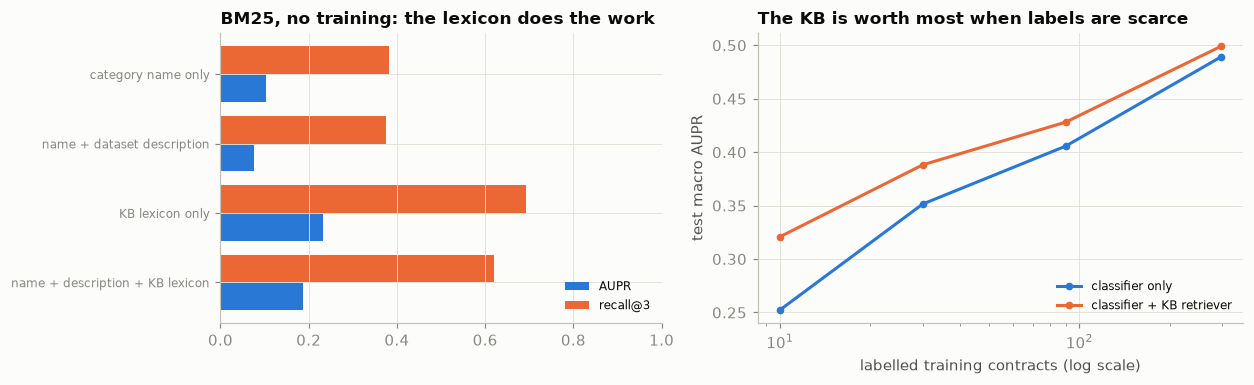

In [15]:
# ---- ablation 1: what the retriever is told (no training at all) ----
QUERIES = {"category name only": CATS,
           "name + dataset description": QUERY_DATASET,
           "KB lexicon only": [" ; ".join(LEXICON[c]) for c in CATS],
           "name + description + KB lexicon": [f"{q} " + " ; ".join(LEXICON[c]) for c, q in zip(CATS, QUERY_DATASET)]}
S_q = {k: np.asarray((W_BM25 @ query_matrix(v).T).todense()) for k, v in QUERIES.items()}
abl_bm25 = pd.DataFrame({k: (lambda e: {"AUPR": e.AUPR.mean(), f"R@{K_HIGHLIGHTS}": e[f"R@{K_HIGHLIGHTS}"].mean(), "AUPR, tail": e.AUPR[TAIL].mean()})(
    eval_scores(S, M["test"])) for k, S in S_q.items()}).T
S_kbq = S_q["name + description + KB lexicon"]

# ---- ablation 2: the classifier with and without the KB retriever's score, as a function of how many labelled contracts exist ----
def zs(S, ref):
    return (S - S[ref].mean(0)) / (S[ref].std(0) + 1e-6)

W_GRID = [0.0, 0.1, 0.25, 0.5, 1.0]
train_ids = contracts.loc[contracts.split == "train", "contract_id"].values
perm = np.random.default_rng(SEED).permutation(train_ids)
curve, t0 = [], time.time()
for n in [10, 30, 90, len(train_ids)]:
    if n == len(train_ids):
        S_n, trm = S_clf, M["train"]
    else:
        trm = chunks.contract_id.isin(perm[:n]).values
        S_n, _ = fit_linear(sp.hstack([TfidfTransformer(sublinear_tf=True).fit(COUNTS[trm]).transform(COUNTS), POS]).tocsr(), trm)
    blends = {w: zs(S_n, trm) + w * zs(S_kbq, M["train"]) for w in W_GRID}
    w_best = max(W_GRID, key=lambda w: eval_scores(blends[w], M["valid"]).AUPR.mean())      # the weight is chosen on validation
    for w, name in [(0.0, "classifier only"), (w_best, "classifier + KB retriever")]:
        e = eval_scores(blends[w], M["test"])
        curve.append({"training contracts": n, "model": name, "KB weight": w, "AUPR": e.AUPR.mean(),
                      f"R@{K_HIGHLIGHTS}": e[f"R@{K_HIGHLIGHTS}"].mean(), "AUPR, tail": e.AUPR[TAIL].mean()})
curve = pd.DataFrame(curve)
W_KB = float(curve.loc[(curve["training contracts"] == len(train_ids)) & (curve.model != "classifier only"), "KB weight"].iloc[0])
S_final = zs(S_clf, M["train"]) + W_KB * zs(S_kbq, M["train"])        # the scorer used from here on
P_final = calibrate(S_final, M["valid"])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
yy = np.arange(len(abl_bm25))
ax.barh(yy + 0.2, abl_bm25.AUPR, height=0.4, color=SERIES[0], label="AUPR")
ax.barh(yy - 0.2, abl_bm25[f"R@{K_HIGHLIGHTS}"], height=0.4, color=SERIES[1], label=f"recall@{K_HIGHLIGHTS}")
ax.set_yticks(yy); ax.set_yticklabels(abl_bm25.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_title("BM25, no training: the lexicon does the work"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
for (name, g), col in zip(curve.groupby("model", sort=False), SERIES):
    ax.plot(g["training contracts"], g.AUPR, "-o", ms=4, lw=2, color=col, label=name)
ax.set_xscale("log"); ax.set_xlabel("labelled training contracts (log scale)"); ax.set_ylabel("test macro AUPR")
ax.set_title("The KB is worth most when labels are scarce"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
print(f"learning curve in {time.time()-t0:.0f}s · KB weight chosen on validation with all training contracts: {W_KB}")
display(abl_bm25.style.format("{:.3f}"))
curve.pivot(index="training contracts", columns="model", values=["AUPR", "AUPR, tail"]).round(3)

The lexicon triples the untrained retriever (AUPR 0.077 → 0.231); the dataset's descriptions dilute it (0.188). For the classifier the gain depends on how many labels exist: +0.069 macro AUPR with 10 training contracts (0.252 → 0.321; the tail doubles, 0.063 → 0.128), +0.037 with 30, +0.022 with 90, +0.010 with 297. The KB is a cold-start and long-tail component, not a general accuracy gain. The scorer from here on adds it at weight 0.25.

**The party–obligation graph** answers "who is bound?" from the extractor's output: roles are the quoted defined terms in the three chunks scored highest for *Parties*; an obligation is a sentence whose subject is a role or "neither party" followed by a modal verb. A defined term can still be a person's name: the graph is personal data (E3).

test contracts: role precision against the annotated Parties text 79% · contracts with ≥ 2 confirmed roles 82% · gold red-flag clause chunks with an obligor (a role or 'either/neither party' as subject) 42%; of the rest, 16% contain a passive modal ('may not be assigned')


,party,red-flag clause,sentences,obligation type
0,Consultant,Ip Ownership Assignment,1,duty
1,Consultant,Anti-Assignment,1,prohibition
2,Company,Ip Ownership Assignment,1,right
3,mutual,Termination For Convenience,1,right


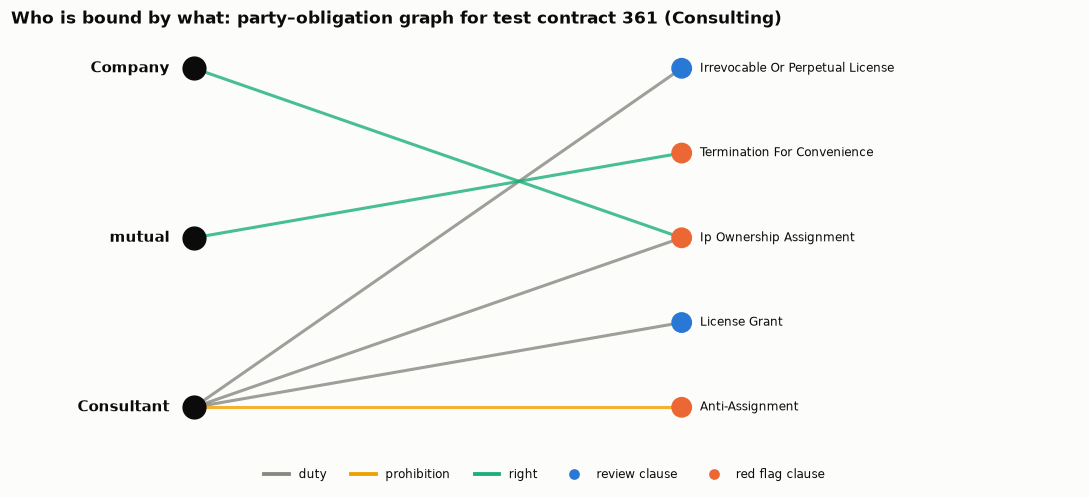

In [16]:
DEF_TERM = re.compile(r"\(([^()]{0,100}?)\)")
QUOTED = re.compile(r"[\"“”']{1,2}\s*([A-Z][A-Za-z0-9&.'\- ]{0,38}[A-Za-z0-9])\s*[\"“”']{1,2}")
NOT_A_PARTY = {"Agreement", "Effective Date", "Parties", "Party", "Execution Date", "Territory", "Products", "Product", "Term",
               "Services", "Commencement Date", "Exhibit", "Schedule"}
MUTUAL = ["[Nn]either [Pp]arty", "[Ee]ither [Pp]arty", "[Ee]ach [Pp]arty", "[Tt]he [Pp]arties", "[Bb]oth [Pp]arties", "[Nn]o [Pp]arty"]
MODAL = r"(shall not|will not|may not|must not|shall|will|must|agrees to|may)"
CHUNKS_OF = {c: np.flatnonzero(chunks.contract_id.values == c) for c in contracts.contract_id}
J_PARTIES = CATS.index("Parties")

def party_roles(cid, top=3):
    '''Defined terms in quotes inside the three chunks the extractor scores highest for 'Parties' (the preamble).'''
    idx = CHUNKS_OF[cid]
    roles = []
    for i in sorted(idx[np.argsort(-S_final[idx, J_PARTIES])[:top]]):
        for m in DEF_TERM.finditer(chunks.text.values[i]):
            for q in QUOTED.finditer(m.group(1)):
                if q.group(1) not in NOT_A_PARTY and q.group(1) not in roles and not q.group(1).isdigit():
                    roles.append(q.group(1))
    return roles

def obligations(cid, roles):
    '''(role, modal, chunk index) for every sentence whose subject is a party role or a mutual phrase.'''
    alts = [re.escape(r) for r in sorted(roles, key=len, reverse=True)] + MUTUAL
    pat = re.compile(r"\b(?:the\s+)?(" + "|".join(alts) + r")(?:\s+and\s+its\s+\w+)?\s+(?:hereby\s+)?" + MODAL + r"\b")
    return [(("mutual" if re.match("|".join(MUTUAL), m.group(1)) else m.group(1)), m.group(2), i)
            for i in CHUNKS_OF[cid] for m in pat.finditer(chunks.text.values[i])]

def obligation_graph(cid, P=P_final, thr=0.5):
    '''Party → clause category edges, typed duty / prohibition / right, from chunks the extractor tags (p ≥ thr).'''
    G = nx.DiGraph()
    for role, modal, i in obligations(cid, party_roles(cid)):
        kind = "prohibition" if "not" in modal else "right" if modal == "may" else "duty"
        for j in np.flatnonzero(P[i] >= thr):
            if TIER[CATS[j]] != "metadata":
                G.add_node(role, kind="party"); G.add_node(CATS[j], kind="clause", tier=TIER[CATS[j]])
                e = G.get_edge_data(role, CATS[j], {"n": 0, "kinds": set()})
                G.add_edge(role, CATS[j], n=e["n"] + 1, kinds=e["kinds"] | {kind}, chunk=int(i))
    return G

# quality of the graph on test contracts, against the annotated Parties spans and the gold red-flag clauses
ps = spans[spans.category == "Parties"]
PASSIVE = re.compile(r"\b(?:shall|will|may|must)(?: not)? be \w+(?:ed|en)\b")      # "may not be assigned", "shall be borne"
rows = []
for cid in contracts.loc[contracts.split == "test", "contract_id"]:
    gold_txt = " ".join(text_of[cid][s:e] for s, e in zip(ps[ps.contract_id == cid].start, ps[ps.contract_id == cid].end))
    roles = party_roles(cid)
    attributed = {i for _, _, i in obligations(cid, roles)}
    red_gold = [i for i in CHUNKS_OF[cid] if Y[i, [CATS.index(c) for c in RED_FLAGS]].any()]
    rows.append({"roles": len(roles), "confirmed": sum(bool(re.search(r"\b" + re.escape(r) + r"\b", gold_txt)) for r in roles),
                 "red-flag chunks": len(red_gold), "attributed": sum(i in attributed for i in red_gold),
                 "unattributed, passive": sum(i not in attributed and bool(PASSIVE.search(chunks.text.values[i])) for i in red_gold)})
pq = pd.DataFrame(rows)
print(f"test contracts: role precision against the annotated Parties text {pq.confirmed.sum() / pq.roles.sum():.0%} · "
      f"contracts with ≥ 2 confirmed roles {(pq.confirmed >= 2).mean():.0%} · gold red-flag clause chunks with an obligor "
      f"(a role or 'either/neither party' as subject) {pq.attributed.sum() / pq['red-flag chunks'].sum():.0%}; of the rest, "
      f"{pq['unattributed, passive'].sum() / (pq['red-flag chunks'] - pq.attributed).sum():.0%} contain a passive modal ('may not be assigned')")

GENERIC = {"Company", "Distributor", "Licensor", "Licensee", "Supplier", "Customer", "Manufacturer", "Agent", "Consultant", "Reseller",
           "Provider", "Client", "Purchaser", "Seller", "Buyer", "Contractor", "Developer", "Publisher", "Sponsor", "Vendor", "Partner"}
cands = [(len(G.edges), cid, G) for cid in contracts.loc[contracts.split == "test", "contract_id"]
         for G in [obligation_graph(cid)] if len(G) and {n for n, d in G.nodes(data=True) if d["kind"] == "party"} <= GENERIC | {"mutual"}]
_, EXAMPLE, G_ex = max(cands, key=lambda t: t[0])
parties_ex = [n for n, d in G_ex.nodes(data=True) if d["kind"] == "party"]
pos_ = nx.bipartite_layout(G_ex, parties_ex, align="vertical", scale=1.0)
fig, ax = plt.subplots(figsize=(10, 4.6))
KIND_COLOR = {"duty": MUTED, "prohibition": SERIES[3], "right": SERIES[2]}
for u_, v_, d in G_ex.edges(data=True):
    kind = sorted(d["kinds"])[0]
    nx.draw_networkx_edges(G_ex, pos_, edgelist=[(u_, v_)], ax=ax, edge_color=KIND_COLOR[kind], width=1.2 + 0.8 * d["n"], arrows=False, alpha=0.8)
clause_nodes = [n for n in G_ex if n not in parties_ex]
nx.draw_networkx_nodes(G_ex, pos_, nodelist=parties_ex, node_color=INK, node_size=220, ax=ax)
nx.draw_networkx_nodes(G_ex, pos_, nodelist=clause_nodes, node_color=[TIER_COLOR[G_ex.nodes[n]["tier"]] for n in clause_nodes], node_size=160, ax=ax)
for n, (x_, y_) in pos_.items():
    ax.text(x_ + (0.06 if n in clause_nodes else -0.08), y_, n, fontsize=8 if n in clause_nodes else 10,
            ha="left" if n in clause_nodes else "right", va="center", color=INK, fontweight="bold" if n in parties_ex else None)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=c_, lw=2.5, label=k_) for k_, c_ in KIND_COLOR.items()] +
          [Line2D([0], [0], marker="o", ls="", color=TIER_COLOR[t_], label=f"{t_} clause") for t_ in ["review", "red flag"]],
          fontsize=8, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.12))
ax.set_xlim(-1.6, 1.9); ax.axis("off")
ax.set_title(f"Who is bound by what: party–obligation graph for test contract {EXAMPLE} ({contracts.ctype[EXAMPLE]})")
plt.tight_layout()
pd.DataFrame([(u_, v_, d["n"], ", ".join(sorted(d["kinds"]))) for u_, v_, d in G_ex.edges(data=True) if TIER[v_] == "red flag"],
             columns=["party", "red-flag clause", "sentences", "obligation type"]).sort_values("sentences", ascending=False).head(8)

Roles are 79 % precise against the annotated Parties text, and 82 % of test contracts get two confirmed roles. Attribution is the weak link: only 42 % of gold red-flag clause chunks have a role or mutual phrase as subject, and only 16 % of the rest contain a passive modal ("may not be assigned"); the other misses need a closer look (task E2).

## 6 · The operating point: twenty highlights per contract

*Part B · Given model · package `review_pack` and `pack_eval`; C3 owns the 20-highlight budget, S1 replaces `generate_risk_summary`.*

The assistant fills the lawyer's fixed number of passages by walking (chunk, red-flag category) pairs from most to least probable until the budget is full; each passage carries the tags that put it there. A red-flag type is *found* only if a passage tagged with it is a clause of that type. The budget for the target is chosen on validation.

budget chosen on validation for 80% red-flag recall: 15 highlights · held-out type reaches it at: 60 (1s)


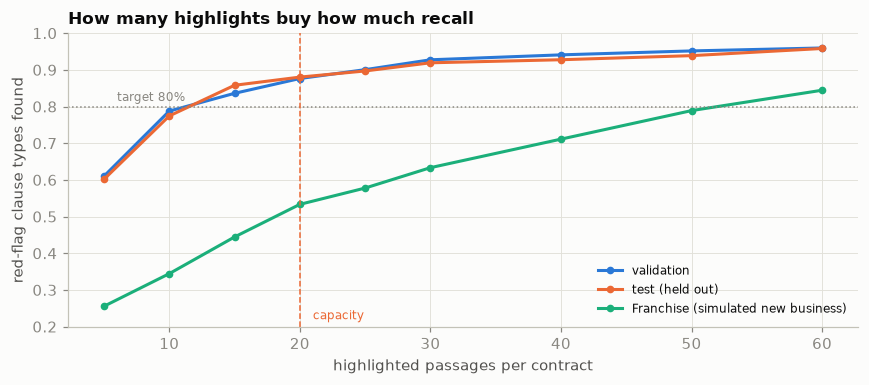

In [17]:
RF = [CATS.index(c) for c in RED_FLAGS]
BUDGETS = [5, 10, 15, 20, 25, 30, 40, 50, 60]

def review_pack(P, cid, budget):
    '''Highlights for one contract: walk the (chunk, red-flag category) pairs from the most to the least likely and keep
    adding chunks until `budget` distinct passages are chosen. Returns {chunk index: set of category tags}.'''
    idx = CHUNKS_OF[cid]; p = P[idx][:, RF]
    chosen = {}
    for a, b in zip(*np.unravel_index(np.argsort(-p, axis=None), p.shape)):
        if idx[a] not in chosen:
            if len(chosen) == budget:
                break
            chosen[idx[a]] = set()
        chosen[idx[a]].add(RF[b])
    return chosen

def pack_eval(P, split, budgets=BUDGETS):
    '''Per contract and budget: red-flag clause types present, found (a highlight tagged with that type is a clause chunk), highlights on target.'''
    rows = []
    for cid in contracts.loc[contracts.split == split, "contract_id"]:
        present = Y[CHUNKS_OF[cid]][:, RF].any(0)
        for B in budgets:
            pack = review_pack(P, cid, B)
            found = np.zeros(len(RF), bool); on_target = 0
            for i, tags in pack.items():
                hit = [RF.index(t) for t in tags if Y[i, t]]
                found[hit] = True; on_target += bool(hit)
            rows.append({"contract_id": cid, "split": split, "budget": B, "present": int(present.sum()),
                         "found": int((found & present).sum()), "highlights": len(pack), "on target": on_target})
    return pd.DataFrame(rows)

t0 = time.time()
packs = pd.concat([pack_eval(P_final, s) for s in ["valid", "test", "held-out type"]])
agg = packs.groupby(["split", "budget"]).sum(numeric_only=True)
agg["red-flag recall"] = agg.found / agg.present
agg["highlights on target"] = agg["on target"] / agg.highlights
B_STAR = int(agg.loc["valid"].query("`red-flag recall` >= @TARGET_RECALL").index.min())          # chosen on validation
cost = lambda B: B * SECONDS_PER_HIGHLIGHT / 3600 * LAWYER_EUR_PER_HOUR

fig, ax = plt.subplots(figsize=(8, 3.6))
for (s_, lab_), col in zip([("valid", "validation"), ("test", "test (held out)"), ("held-out type", f"{HELD_OUT_TYPE} (simulated new business)")], SERIES):
    a_ = agg.loc[s_]
    ax.plot(a_.index, a_["red-flag recall"], "-o", ms=4, lw=2, color=col, label=lab_)
ax.axhline(TARGET_RECALL, color=MUTED, ls=":", lw=1); ax.text(6, TARGET_RECALL + 0.015, f"target {TARGET_RECALL:.0%}", color=MUTED, fontsize=8)
ax.axvline(LAWYER_HIGHLIGHTS, color=SERIES[1], ls="--", lw=1); ax.text(LAWYER_HIGHLIGHTS + 1, 0.22, "capacity", color=SERIES[1], fontsize=8)
ax.set_ylim(0.2, 1.0); ax.set_xlabel("highlighted passages per contract"); ax.set_ylabel("red-flag clause types found")
ax.set_title("How many highlights buy how much recall"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
op = agg.loc[[(s_, B) for s_ in ["valid", "test", "held-out type"] for B in sorted({B_STAR, LAWYER_HIGHLIGHTS})]][["red-flag recall", "highlights on target"]]
op["lawyer minutes"] = [B * SECONDS_PER_HIGHLIGHT / 60 for _, B in op.index]
op["€ per month"] = [cost(B) * CONTRACTS_PER_MONTH for _, B in op.index]
ho_ok = agg.loc["held-out type"].query("`red-flag recall` >= @TARGET_RECALL").index
print(f"budget chosen on validation for {TARGET_RECALL:.0%} red-flag recall: {B_STAR} highlights · "
      f"held-out type reaches it at: {int(ho_ok.min()) if len(ho_ok) else 'none of the budgets tried'} ({time.time()-t0:.0f}s)")
op.style.format({"red-flag recall": "{:.1%}", "highlights on target": "{:.1%}", "lawyer minutes": "{:.0f}", "€ per month": "€{:,.0f}"})

On validation the 80 % target needs 15 passages (83.6 %), about 22 minutes. At the board's 20 the lawyer sees 88.0 % of the red-flag types present in test contracts, and 26.3 % of passages are on target, about €4,000 a month at the assumed rate and volume (C3). The board must also hear that one present red-flag type in eight is not in the highlights, and the assistant cannot say which.

The review pack is what the lawyer receives and all a generation step may see (S1): each passage cites `[contract:start-end]`, and advice requests are refused first.

In [18]:
# The review pack a lawyer receives, and the contract a generation step must honour (task S1). No LLM is called here.
def pack_table(cid, budget=LAWYER_HIGHLIGHTS):
    rows = []
    for i, tags in review_pack(P_final, cid, budget).items():
        s_, e_ = int(chunks.start.values[i]), int(chunks.end.values[i])
        for t_ in tags:
            rows.append({"category": CATS[t_], "p": float(P_final[i, t_]), "cite": f"[{cid}:{s_}-{e_}]",
                         "passage": re.sub(r"\s+", " ", text_of[cid][s_:e_])[:110] + "…"})
    return pd.DataFrame(rows).sort_values("p", ascending=False)

ADVICE = re.compile(r"\b(should (we|i)|safe to sign|enforceab\w*|advise|recommend\w*|legal advice|negotiat\w*|is (this|it) (ok|fine|legal))\b", re.I)

def generate_risk_summary(cid, question="Summarise the red-flag clauses in this contract."):
    '''Stub: assembles what a generation step may see. Replace with an LLM call behind a versioned prompt (task S1),
    keeping the citation contract (every claim cites [contract:start-end]) and the refusal path.'''
    if ADVICE.search(question):
        return {"refused": True, "reason": "This assistant highlights clauses for a lawyer; it does not give legal advice."}
    pack = pack_table(cid)
    return {"refused": False, "prompt_version": 1, "question": question, "citations": pack.cite.unique().tolist(),
            "not_found_in_highlights": sorted(set(RED_FLAGS) - set(pack.category)),
            "instruction": "Summarise only the cited passages; quote the citation after each sentence; say which red flags "
                           "were not found in the highlights; do not assess enforceability or recommend signing."}

def citations_exact(cid, pack):
    return all(text_of[cid][int(c.split(":")[1].split("-")[0]):int(c.split("-")[1][:-1])] == text_of[cid][s:e]
               for c, (s, e) in zip(pack.cite, [(int(c.split(":")[1].split("-")[0]), int(c.split("-")[1][:-1])) for c in pack.cite]))

GOLDEN = spans[spans.contract_id.isin(contracts.loc[contracts.split == "test", "contract_id"]) & spans.category.isin(RED_FLAGS)]
ex_pack = pack_table(EXAMPLE)
out = generate_risk_summary(EXAMPLE)
print(f"golden set for the generation step: {len(GOLDEN):,} red-flag clause spans in {GOLDEN.contract_id.nunique()} test contracts · "
      f"example contract {EXAMPLE}: {len(ex_pack)} tagged highlights, {len(out['not_found_in_highlights'])} red flags not found")
DIRECT = ["Should we sign this contract as it stands?", "Is the non-compete enforceable?"]
PARAPHRASED = ["Can we live with this liability cap?", "Would you sign this?", "Do we need to push back on the non-compete?"]
for q in ["Summarise the red-flag clauses in this contract."] + DIRECT + PARAPHRASED:
    print(f"  {q!r:55s} → {'refused' if generate_risk_summary(EXAMPLE, q)['refused'] else 'answered from ' + str(len(out['citations'])) + ' citations'}")
print(f"advice requests refused by the keyword stub: {sum(generate_risk_summary(EXAMPLE, q)['refused'] for q in DIRECT)} of {len(DIRECT)} direct, "
      f"{sum(generate_risk_summary(EXAMPLE, q)['refused'] for q in PARAPHRASED)} of {len(PARAPHRASED)} paraphrased")
ex_pack.head(6)

golden set for the generation step: 683 red-flag clause spans in 88 test contracts · example contract 361: 25 tagged highlights, 5 red flags not found
  'Summarise the red-flag clauses in this contract.'      → answered from 20 citations
  'Should we sign this contract as it stands?'            → refused
  'Is the non-compete enforceable?'                       → refused
  'Can we live with this liability cap?'                  → answered from 20 citations
  'Would you sign this?'                                  → answered from 20 citations
  'Do we need to push back on the non-compete?'           → answered from 20 citations
advice requests refused by the keyword stub: 2 of 2 direct, 0 of 3 paraphrased


,category,p,cite,passage
1,Cap On Liability,0.999982,[361:21392-21893],10. Limitation of Liability. IN NO EVENT SHALL COMPANY BE LIABLE TO CONSULTA...
2,Cap On Liability,0.994702,[361:21894-22138],IN NO EVENT SHALL COMPANY'S AGGREGATE LIABILITY ARISING OUT OF OR IN CONNECT...
3,Ip Ownership Assignment,0.987630,[361:8064-8313],Consultant also agrees to promptly make full written disclosure to the Compa...
4,Termination For Convenience,0.987520,[361:17723-17936],"7.2. Termination. Either Party may terminate this Agreement, with or without..."
5,Non-Compete,0.864358,[361:14425-14914],4.2 Covenant Not to Compete. Consultant does not presently perform or intend...
7,Anti-Assignment,0.787925,[361:24530-24676],"Except as may otherwise be provided in this Agreement, Consultant may not se..."


The keyword stub refuses both direct advice requests and none of the three paraphrases ("Would you sign this?"): a keyword list is not a refusal policy, which is why S1 evaluates paraphrases. Its golden set holds 683 red-flag clause spans in 88 test contracts.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: a contract type the extractor has never seen (simulated)

*Part C · Productionise · what your monitoring plan must catch: an unseen contract type and recall from corrections (C5).*

Nothing here drifts with time (Section 3). What changes for a legal team is the business mix: a company that starts franchising receives contracts drafted differently. To simulate it, the 15 franchise agreements never entered training.

In [19]:
# per-category effect of the new contract type, at the lawyer's capacity
cat_rows = []
for s_ in ["test", "held-out type"]:
    for cid in contracts.loc[contracts.split == s_, "contract_id"]:
        pack, present = review_pack(P_final, cid, LAWYER_HIGHLIGHTS), Y[CHUNKS_OF[cid]][:, RF].any(0)
        tagged = {t for i, tags in pack.items() for t in tags if Y[i, t]}
        for k, j in enumerate(RF):
            if present[k]:
                cat_rows.append({"split": s_, "category": CATS[j], "found": j in tagged})
cat_cmp = pd.DataFrame(cat_rows).pivot_table(index="category", columns="split", values="found", aggfunc=["mean", "size"])
cat_cmp.columns = [f"{a} · {b}" for a, b in cat_cmp.columns]
cat_cmp = cat_cmp.rename(columns=lambda c: c.replace("mean", "found").replace("size", "clauses"))
cat_cmp["drop"] = cat_cmp["found · test"] - cat_cmp["found · held-out type"]
e_ho, e_te = eval_scores(S_final, M["held-out type"]), eval_scores(S_final, M["test"])
print(f"{HELD_OUT_TYPE} contracts (never in training): macro AUPR {e_ho.AUPR.mean():.3f} vs {e_te.AUPR.mean():.3f} on test · "
      f"red-flag recall at {LAWYER_HIGHLIGHTS} highlights {agg.loc[('held-out type', LAWYER_HIGHLIGHTS), 'red-flag recall']:.1%} vs "
      f"{agg.loc[('test', LAWYER_HIGHLIGHTS), 'red-flag recall']:.1%}")
display(cat_cmp.sort_values("drop", ascending=False).head(6).style.format({c: ("{:.0%}" if "found" in c or c == "drop" else "{:.0f}") for c in cat_cmp.columns}))

# what it misses: the most-missed red flag in the new type, the clause versus what the extractor highlighted instead
worst = cat_cmp[cat_cmp["clauses · held-out type"] >= 5].sort_values("drop", ascending=False).index[0]   # a miss seen at least five times
j = CATS.index(worst)
for cid in contracts.loc[contracts.split == "held-out type", "contract_id"]:
    idx = CHUNKS_OF[cid]
    gold_i = [i for i in idx if Y[i, j]]
    pack = review_pack(P_final, cid, LAWYER_HIGHLIGHTS)
    if gold_i and not any(Y[i, j] and j in tags for i, tags in pack.items()):
        g_ = max(gold_i, key=lambda i: P_final[i, j])
        p_cut = min(max(P_final[i, t] for t in tags) for i, tags in pack.items())
        took = pd.Series([CATS[t] for tags in pack.values() for t in tags]).value_counts().head(3)
        print(f"\n{worst} in {HELD_OUT_TYPE.lower()} contract {cid}: the annotated clause ranks {int((P_final[idx, j] > P_final[g_, j]).sum()) + 1} "
              f"of {len(idx)} chunks for this category, at p = {P_final[g_, j]:.2f}; the {LAWYER_HIGHLIGHTS}th passage in the pack has p = {p_cut:.2f}.")
        print("  slots taken by:", ", ".join(f"{c} ({n})" for c, n in took.items()))
        print("  the clause    :", re.sub(r"\s+", " ", chunks.text.values[g_])[:200], "…")
        break
p_best = {s_: np.mean([P_final[CHUNKS_OF[c]][:, j_][Y[CHUNKS_OF[c], j_] == 1].max() for c in contracts.loc[contracts.split == s_, "contract_id"]
                       for j_ in RF if Y[CHUNKS_OF[c], j_].any()]) for s_ in ["test", "held-out type"]}
print(f"\nmean probability of the best clause chunk, red flags present: test {p_best['test']:.2f} · {HELD_OUT_TYPE.lower()} {p_best['held-out type']:.2f}")

Franchise contracts (never in training): macro AUPR 0.399 vs 0.499 on test · red-flag recall at 20 highlights 53.3% vs 88.0%


,found · held-out type,found · test,clauses · held-out type,clauses · test,drop
category,,,,,
Uncapped Liability,0%,95%,1,21,95%
Cap On Liability,17%,98%,6,56,82%
Ip Ownership Assignment,25%,89%,8,27,64%
Exclusivity,29%,90%,7,31,62%
Change Of Control,12%,67%,8,18,54%
Anti-Assignment,60%,99%,10,71,39%



Cap On Liability in franchise contract 30: the annotated clause ranks 1 of 716 chunks for this category, at p = 0.33; the 20th passage in the pack has p = 0.61.
  slots taken by: Rofr/Rofo/Rofn (6), Liquidated Damages (5), Non-Compete (3)
  the clause    : Each of us waives any right to or claim of punitive, exemplary, multiple, or consequential damages against the other in litigation and agrees to be limited to the recovery of actual damages sustained. …

mean probability of the best clause chunk, red flags present: test 0.64 · franchise 0.48


On franchise agreements macro AUPR falls from 0.499 to 0.399, and red-flag recall at 20 highlights from 88.0 % to 53.3 %; the 80 % target is reached only at 60 passages. Liability, IP ownership, exclusivity and change of control fail most (Cap On Liability: 1 of 6 franchise contracts, 98 % on test). In the example the clause still ranks first for its category, but at p = 0.33 where the twentieth passage needs 0.61. Calibration learned on familiar drafting does not transfer (a present red flag's best chunk averages 0.48 on franchise agreements, 0.64 on test).

Now a simulated year: from month 7, franchise agreements rise from 10 % to 50 % of intake, resampled from the test and held-out pools (**simulated**: the ramp is an assumption).

type check (C = 30): flags 10% of validation, 10% of test (allowed ≤ 15%: quiet) and 33% of franchise agreements


month,1,2,3,4,5,6,7,8,9,10,11,12
"unseen type, by title (by construction)",0.000,0.000,0.000,0.000,0.000,0.000,0.100,0.200,0.300,0.400,0.500,0.500
type-check doubt,0.075,0.050,0.125,0.100,0.050,0.100,0.025,0.100,0.200,0.100,0.225,0.100
novelty,0.598,0.606,0.586,0.604,0.578,0.585,0.569,0.606,0.564,0.626,0.610,0.614
confident flags / contract,3.125,3.175,3.200,3.175,2.675,3.375,3.425,2.900,3.975,3.200,3.675,3.600
red-flag recall (after review),0.867,0.811,0.835,0.908,0.899,0.857,0.784,0.717,0.746,0.786,0.675,0.695


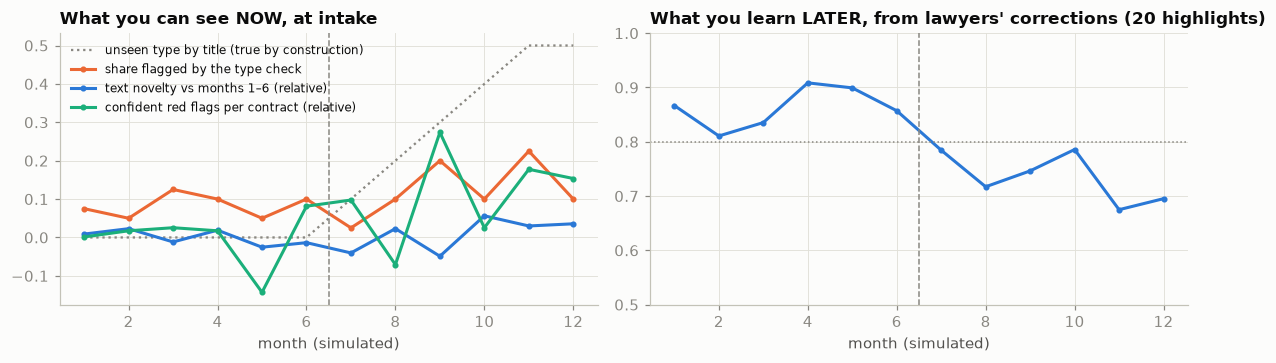

In [20]:
# A simulated year of incoming contracts: from month 7, the business starts signing franchise agreements (SIMULATED:
# contracts are resampled with replacement from the test and held-out pools; the ramp is an assumption, not data).
MONTHS, SHARE = 12, [0, 0, 0, 0, 0, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.5]
train_types = set(contracts.loc[contracts.split == "train", "ctype"])

# An intake type check that could fail: a contract-type classifier trained on training contracts. Its doubt threshold
# is set on validation (it may flag TYPE_DOUBT_RATE of familiar contracts) and it must stay that quiet on test contracts.
cdf = contracts.set_index("contract_id")
SPL = {s_: (cdf.split == s_).values for s_ in ["train", "valid", "test", "held-out type"]}
XT = TfidfVectorizer(min_df=3, max_features=30_000, sublinear_tf=True, token_pattern=TOKEN, dtype=np.float32).fit(cdf.text[SPL["train"]]).transform(cdf.text)
type_fit = lambda C: LogisticRegression(C=C, max_iter=2000).fit(XT[SPL["train"]], cdf.ctype[SPL["train"]])
C_TYPE = max([1, 10, 30], key=lambda C: (type_fit(C).predict(XT[SPL["valid"]]) == cdf.ctype[SPL["valid"]]).mean())   # chosen on validation
type_conf = type_fit(C_TYPE).predict_proba(XT).max(1)
DOUBT_THR = np.quantile(type_conf[SPL["valid"]], TYPE_DOUBT_RATE)
doubt = type_conf < DOUBT_THR
n_te = SPL["test"].sum(); allowed = binom.ppf(0.95, n_te, TYPE_DOUBT_RATE) / n_te
print(f"type check (C = {C_TYPE}): flags {doubt[SPL['valid']].mean():.0%} of validation, {doubt[SPL['test']].mean():.0%} of test "
      f"(allowed ≤ {allowed:.0%}: {'quiet' if doubt[SPL['test']].mean() <= allowed else 'FAILS'}) and {doubt[SPL['held-out type']].mean():.0%} "
      f"of {HELD_OUT_TYPE.lower()} agreements")
dv = doc_vec.tocsr()                                                      # TF-IDF contract vectors from Section 1 (unit length)
tr_rows = contracts.index[contracts.split == "train"]
per_contract = packs[packs.budget == LAWYER_HIGHLIGHTS].set_index("contract_id")
sig = pd.DataFrame({"unseen type": (~contracts.ctype.isin(train_types)).astype(int).values, "type doubt": doubt.astype(int),
                    "novelty": 1 - np.asarray((dv @ dv[tr_rows].T).max(1).todense()).ravel(),
                    "confident flags": [int((P_final[CHUNKS_OF[c]][:, RF].max(0) >= 0.5).sum()) for c in contracts.contract_id]},
                   index=contracts.contract_id)
rng_s = np.random.default_rng(SEED)
pool_te = contracts.loc[contracts.split == "test", "contract_id"].values
pool_ho = contracts.loc[contracts.split == "held-out type", "contract_id"].values
stream = []
for m_, share in zip(range(1, MONTHS + 1), SHARE):
    n_new = int(round(share * CONTRACTS_PER_MONTH))
    ids_ = np.r_[rng_s.choice(pool_te, CONTRACTS_PER_MONTH - n_new), rng_s.choice(pool_ho, n_new)]
    pc = per_contract.loc[ids_]
    stream.append({"month": m_, "unseen type, by title (by construction)": sig.loc[ids_, "unseen type"].mean(),
                   "type-check doubt": sig.loc[ids_, "type doubt"].mean(), "novelty": sig.loc[ids_, "novelty"].mean(),
                   "confident flags / contract": sig.loc[ids_, "confident flags"].mean(),
                   "red-flag recall (after review)": pc.found.sum() / pc.present.sum()})
stream = pd.DataFrame(stream).set_index("month")
base = stream.loc[1:6].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.plot(stream.index, stream["unseen type, by title (by construction)"], ":", lw=1.5, color=MUTED, label="unseen type by title (true by construction)")
ax.plot(stream.index, stream["type-check doubt"], "-o", ms=3, lw=2, color=SERIES[1], label="share flagged by the type check")
ax.plot(stream.index, stream["novelty"] / base["novelty"] - 1, "-o", ms=3, lw=2, color=SERIES[0], label="text novelty vs months 1–6 (relative)")
ax.plot(stream.index, stream["confident flags / contract"] / base["confident flags / contract"] - 1, "-o", ms=3, lw=2, color=SERIES[2], label="confident red flags per contract (relative)")
ax.axvline(6.5, color=MUTED, ls="--", lw=1); ax.set_xlabel("month (simulated)")
ax.set_title("What you can see NOW, at intake"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.plot(stream.index, stream["red-flag recall (after review)"], "-o", ms=3, lw=2, color=SERIES[0])
ax.axhline(TARGET_RECALL, color=MUTED, ls=":", lw=1); ax.axvline(6.5, color=MUTED, ls="--", lw=1)
ax.set_ylim(0.5, 1); ax.set_xlabel("month (simulated)")
ax.set_title(f"What you learn LATER, from lawyers' corrections ({LAWYER_HIGHLIGHTS} highlights)")
plt.tight_layout()
stream.round(3).T

At intake, text novelty and confident red flags per contract barely move. The title-based type check fires, but **by construction**: the simulation is defined by type, and the title rule was written from the README's type list. The check that could fail is the type classifier: set on validation to flag 10 % of familiar contracts, it stays quiet on test (10 %) and flags 33 % of franchise agreements. At 40 contracts a month that is too weak to show as a trend (5–12.5 % flagged a month before the change, 2.5–22.5 % after), so use it per contract, to route a flagged contract to full review. In production, type comes from intake metadata or a classifier with its own error. Later, lawyers' corrections show recall falling from 0.81–0.91 to 0.68–0.79, the delayed confirmation (C5).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

Updated with what this notebook found:

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/contract_review/` (chunker, extractor, `kb/`, review pack); `POST /review`: text in, cited highlights and "not found" out; model, 94,542-term vocabulary, calibrators, taxonomy versioned together |
| Monitoring (S04) | Now: type-check doubt per contract (10 % on validation and test, 33 % on franchise; no monthly trend), confident red flags, latency, cost. Later: red-flag recall from corrections (0.81–0.91, then 0.68–0.79). Doubtful type → full manual review |
| CI/CD gate (S05) | Frozen test contracts (SHA-256 `c123abd3dad0e865…`): red-flag recall at 20 highlights (0.880 today), recall@3 per category with ≥ 10 test contracts, SHACL shapes; thresholds set by legal ops, not tuned on test |
| MLflow tracking and registry (S06) | Chunker, `NEG_SAMPLE`, C, KB weight (0.25), lexicon version, per-category metrics, recall by budget, holdout SHA; `champion` / `challenger` |
| Offline / online training and serving | Online per contract (seconds); offline retraining from lawyers' corrections (active learning) |
| Data and model drift | No drift by filing year (0.494 before 2010, 0.527 after, within noise). A new contract type is the drift: franchise agreements (simulated) cut recall at 20 highlights from 88.0 % to 53.3 % |
| Knowledge base and context (S07–S09) | 499 triples, 13 relations, 252 lexicon terms, SHACL-valid; 7 annotation inconsistencies. Lexicon triples untrained BM25 (AUPR 0.077 → 0.231); KB adds +0.069 at 10 training contracts, +0.010 at 297. Obligor found for 42 % of red-flag clause chunks |
| GenAI and context engineering (S10–S11) | Risk summary from the review pack only, citing `[contract:start-end]`; advice refusal tested on paraphrases; 683-span golden set; citation exactness, judge, injection tests, cost |
| Governance | Not legal advice (keyword refusal stub: 2 of 2 direct requests, 0 of 3 paraphrases refused); CC BY 4.0 attribution to The Atticus Project; EDGAR contracts, no licence representation; e-mails and phones masked; AI Act position (E3) |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with tests.** Retest Trap 1 on all 41 categories and several seeds; tests that fail if a contract family crosses splits or if the chunker cuts more than 7 % of clauses; evaluation reporting macro, tail and all-pairs precision; SHACL shapes run on predictions too.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `LAWYER_HIGHLIGHTS` (5–60), `SECONDS_PER_HIGHLIGHT`, `TARGET_RECALL` and the red-flag list; test one reserved passage per red-flag category; show the recall–cost frontier. Write the ADR; a legal-operations lead signs off the red-flag list.
- **C4 — Package, container and gate.** `src/contract_review/`, `POST /review`, Dockerfile, `compose.yaml`; `make ci` gating red-flag recall at 20 highlights and per-category recall@3 on the frozen test contracts, refusing a holdout whose SHA-256 changed (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs, a `champion` alias, a model card (EDGAR contracts, US drafting, the red-flag assumption, the tail, not legal advice) and a monitoring plan: the type check as the intake alarm (with its false-alarm rate), recall from corrections as the delayed signal, the retraining trigger, rollback (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation, properly (Sessions 07–09).** Version taxonomy and lexicon as Turtle with shapes in CI, use the relations at inference, and report the gain with and without KB context by contract type, franchise agreements included.
- **E2 — Who is bound.** Add a SHACL shape requiring one obligor, or "mutual", per obligation, report the share of obligations that fail it (42 % are attributed today), and design the lawyer review step for the failures.
- **E3 — Governance and the AI Act.** What may the service log, and for how long? Write the attribution and licence position, and ask counsel: does clause highlighting for a company's own lawyers fall within any Annex III area?
- **E4 — Equal attention across contract types.** Red-flag recall at 20 highlights per contract type and era, with intervals: which types need a bigger budget or manual review?

### Stretch

- **S1 — A risk summary with exact citations.** Replace `generate_risk_summary` with an LLM call behind a versioned prompt that sees only the review pack and returns `{findings: [{category, sentence, citation}], not_found}`. Evaluate on the 683-span golden set: citation exactness, faithfulness (a judge calibrated on 50 hand-checked summaries), refusal including paraphrased advice requests, prompt injection, cost (Sessions 10–11).
- **S2 — Online serving with streaming intake.** `POST /review` behind a queue; latency and cost per contract at 40 and 400 a month, with and without the S1 summary step.
- **S3 — A feedback loop from lawyers.** Design how lawyers' corrections are captured (schema, audit log, who may change a label) and how they would feed a scheduled retrain of the given model; simulate the volume, not the learning.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; no data or contract text committed
- [ ] `README.md` states the source, the CC BY 4.0 attribution to The Atticus Project, EDGAR provenance, the split rule and the held-out type
- [ ] Grouped split, chunker and evaluation under test; traps removed; macro, tail and all-pairs metrics
- [ ] Operating point and red-flag list chosen from capacity, with the ADR
- [ ] CI gate on the fingerprinted holdout; registered model, model card; monitoring plan with the type check
- [ ] Taxonomy and shapes versioned; KB ablation by training-set size
- [ ] One-page recommendation for legal operations: what it finds, misses and costs
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `scipy`, `networkx`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No LLM needed.
- Hendrycks, D., Burns, C., Chen, A., Ball, S. (2021). *CUAD: An Expert-Annotated NLP Dataset for Legal Contract Review.* arXiv:2103.06268. Data: The Atticus Project, CUAD v1, CC BY 4.0; contracts from SEC EDGAR.
- Rajpurkar, P., Jia, R., Liang, P. (2018). *Know What You Don't Know: Unanswerable Questions for SQuAD.* ACL.
- Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* · W3C (2017). *SHACL.* · Huyen, C. (2024). *AI Engineering*, Ch. 4, 6.

In [21]:
import sys
print(f"python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · "
      f"networkx {nx.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python 3.13.13 · pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 181s
